# Toy Example

**Dataset**: simulated counts for 300 points and 200 features from 4 groups (generated by `examples/prep_toy/generate_toy.ipynb`).
**Clustering**: NMF and LDA (mixed membership) and K-means (hard), aligned with *Clumppling* and compared with *compModels*.

We cover:
1. Running *Clumppling* and *compModels*
2. Single-model analysis (K-means, NMF)
3. Feature analysis
4. Multi-model comparison
5. Comparison with reference labels

## Setup

In [1]:
from pathlib import Path
import ace_of_clust as aoc

base_dir =  Path("../..").resolve()
example_data_dir = base_dir / "examples" / "data" / "toy"


Note: to be able to use all crisp methods, you need to install some additional packages:  {'bayanpy', 'graph_tool', 'wurlitzer', 'infomap'}
Note: to be able to use all crisp methods, you need to install some additional packages:  {'ASLPAw', 'pyclustering'}
Note: to be able to use all crisp methods, you need to install some additional packages:  {'wurlitzer', 'infomap'}


## Run *Clumppling*

Align the runs of each model (clustering algorithm) separately.

In [2]:
for method_lb in ["nmf", "lda", "kmeans"]:

    cls_dir = example_data_dir / "clustering" / method_lb
    align_dir = example_data_dir / "aligned" / method_lb

    aoc.run_clumppling(
        input_dir=cls_dir,
        output_dir=align_dir,
        fmt="generalQ",
        extension=".Q",
        vis=False,
        use_rep=True,
        use_best_pair=True,
        merge=True,
        cd_res=1.0,
        comm_max=0.1,
    )


2026-11-05 14:40:12 - INFO     =================== CLUMPPLING ===================


2026-11-05 14:40:12 - INFO     --------------------------------------------------


2026-11-05 14:40:12 - INFO     Parameters:


2026-11-05 14:40:12 - INFO       input: examples/data/toy/clustering/nmf


2026-11-05 14:40:12 - INFO       output: examples/data/toy/aligned/nmf


2026-11-05 14:40:12 - INFO       format: generalQ


... (251 outputs left out)

2026-11-05 14:40:13 - INFO     ==================================================


2026-11-05 14:40:13 - INFO     -----------------Zipping outputs------------------


2026-11-05 14:40:13 - INFO     ==================================================


2026-11-05 14:40:13 - INFO     Total Time: 0.595s


## Run *compModels*

In [3]:
model_comp_dir = example_data_dir / "comp_models" / "toy"
model_comp_output_dir = example_data_dir / "comp_models" / "toy_output"
models = ["nmf", "lda", "kmeans"]
suffixes = ["rep"] * len(models)

model_dirs = [
    example_data_dir / "aligned" / "nmf",
    example_data_dir / "aligned" / "lda",
    example_data_dir / "aligned" / "kmeans",
]

# Prepare qfilelist / qnamelist / mode_stats files
qfilelists, qnamelists, mode_stats_files = aoc.prepare_compmodels(
    models=models,
    model_dirs=model_dirs,
    comp_dir=model_comp_dir,
    suffixes=suffixes,
)


Optionally, add the ground truth as a reference "model".

In [4]:
gt_qfile = example_data_dir / "ground_truth.Q"
gt_qfile_file = example_data_dir / "comp_models" / f"toy" / "truth.qfilelist"
with open(gt_qfile_file, "w") as f:
    f.write(str(gt_qfile) + "\n")
gt_qname_file = example_data_dir / "comp_models" / f"toy" / "truth.qnamelist"
with open(gt_qname_file, "w") as f:
    f.write("ground.truth\n")
qfilelists.insert(0, str(gt_qfile_file))
qnamelists.insert(0, str(gt_qname_file))
gt_mode_stats_file = model_comp_dir / "dummy" / "mode_stats.txt"
gt_mode_stats_file.parent.mkdir(parents=True, exist_ok=True)
with open(gt_mode_stats_file, "w") as f:
    f.write('Mode,Representative,Size,Cost,Performance\n')
    f.write("K4M1,ground.truth,1,0.0,1.0\n")
mode_stats_files.insert(0, gt_mode_stats_file)
models.insert(0, "ground.truth")

In [5]:
aoc.run_comp_models(
    models=models,
    comp_dir=model_comp_dir,
    output_dir=model_comp_output_dir,
    vis=False,
    bg_colors=None,   
    include_sim_in_label=True,
    ind_labels="",    
    qfilelists=qfilelists,
    qnamelists=qnamelists,
    mode_stats_files=mode_stats_files,
)

2026-11-05 14:40:13 - INFO     Output directory 'examples/data/toy/comp_models/toy_output' exists and is not empty. Attempting to remove it.


2026-11-05 14:40:13 - INFO     Removed existing output directory 'examples/data/toy/comp_models/toy_output'.


2026-11-05 14:40:13 - INFO     Created output directory 'examples/data/toy/comp_models/toy_output'.


2026-11-05 14:40:13 - INFO     >>> Loading replicate names and matrices from each model 


2026-11-05 14:40:13 - INFO     Successfully loaded 1 Q files.


2026-11-05 14:40:13 - INFO     Successfully loaded 3 Q files.


... (11 outputs left out)

2026-11-05 14:40:15 - INFO     >>> Plotting alignment results ...................


2026-11-05 14:40:15 - INFO     -----------------Zipping outputs------------------


2026-11-05 14:40:15 - INFO     --------------------Completed---------------------


2026-11-05 14:40:15 - INFO     ==================================================


## Load Data

In [6]:
from importlib.resources import files
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

### Colors

Any list of colors works; here, the package defaults.

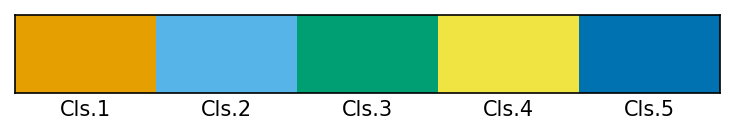

In [7]:
path = files("ace_of_clust").joinpath("resources/default_colors.txt")
default_colors = path.read_text().splitlines()
fig, _, _  = aoc.plot_discrete_colorbar(default_colors[:5], K_max=5)

### Ground-Truth Labels

In [8]:
truth_labels_file = example_data_dir / "clustering" / "kmeans" / "groups.txt"
truth_labels = np.loadtxt(truth_labels_file, dtype=int)
print(pd.Series(truth_labels).value_counts())

0    100
2     80
3     70
1     50
Name: count, dtype: int64


### Data and Coordinates

Coordinates are used only for 2D plots (e.g. UMAP for scRNA-seq, spatial coordinates for spatial data). The toy data have none, so we use the first two principal components.

In [9]:
truth_X_file = example_data_dir / "X.txt"
truth_X = np.loadtxt(truth_X_file, delimiter=",")
X_pca = PCA(n_components=2).fit_transform(truth_X)
feature_names = [f"Feature{i+1}" for i in range(truth_X.shape[1])]

### Ground-Truth Visualization

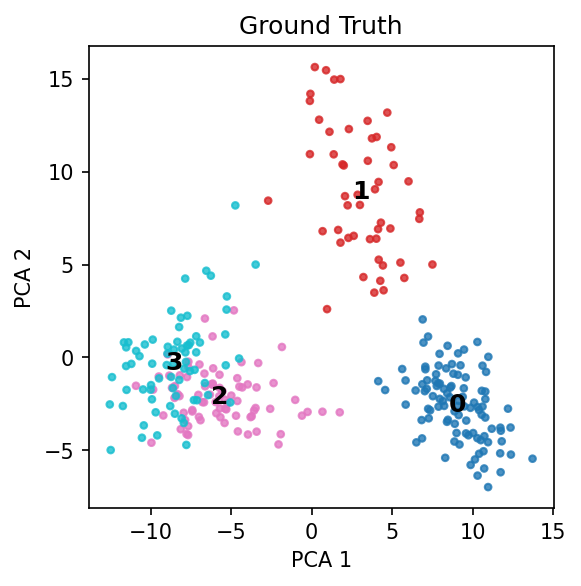

In [10]:
plt.figure(figsize=(4,4), dpi=150)
plt.scatter(X_pca[:,0], X_pca[:,1], c=truth_labels, cmap='tab10', s=10, alpha=0.8)
# label each group in the center
for label in np.unique(truth_labels):
    mask = truth_labels == label
    x_center = X_pca[mask, 0].mean()
    y_center = X_pca[mask, 1].mean()
    plt.text(x_center, y_center, str(label), color='black', fontsize=12, ha='center', va='center', weight='bold')
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("Ground Truth")
plt.show()

In [11]:
from clumppling.utils import get_uniq_lb_sep
# get group separations based on truth labels
grp_lbs, grp_indices, grp_seps = get_uniq_lb_sep(truth_labels)

### Feature Values

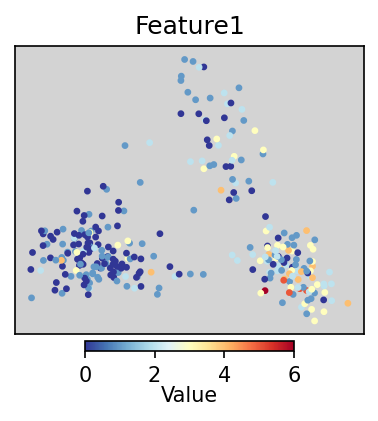

In [12]:
i_g = 0 # first feature
feature_val = truth_X[:, i_g]
fig, ax = plt.subplots(1, 1, figsize=(3,3), dpi=150)
fig = aoc.plot_feature_count(feature_val, X_pca, feature_name=feature_names[i_g], ax=ax,
                             cmap="RdYlBu_r", cbar_label="Value")

## Model 1: K-means

In [13]:
align_dir = example_data_dir / "aligned" / "kmeans"
cls_dir = example_data_dir / "clustering" / "kmeans"

### Load Results

In [14]:
results = aoc.load_clumppling_results(
    align_dir=align_dir,
    suffix="rep",
    cls_dir=cls_dir,
    load_P=False,  
)

# compute pairwise mappings between modes
pair_mappings = aoc.get_mode_pair_mappings(
    mode_names=results.modes,
    all_modes_alignment=results.all_modes_alignment,
    alignment_acrossK=results.alignment_acrossK,
)

In [15]:
results.mode_stats

,Mode,Representative,Size,Cost,Performance
0,K3M1,1_K3R1,5,1.069893e-32,1.000000
1,K4M1,6_K4R1,5,5.266667e-02,0.773355
2,K5M1,11_K5R1,1,0.000000e+00,1.000000
3,K5M2,12_K5R2,1,0.000000e+00,1.000000
4,K5M3,13_K5R3,1,0.000000e+00,1.000000
5,K5M4,14_K5R4,1,0.000000e+00,1.000000
6,K5M5,15_K5R5,1,0.000000e+00,1.000000


### Cluster Memberships

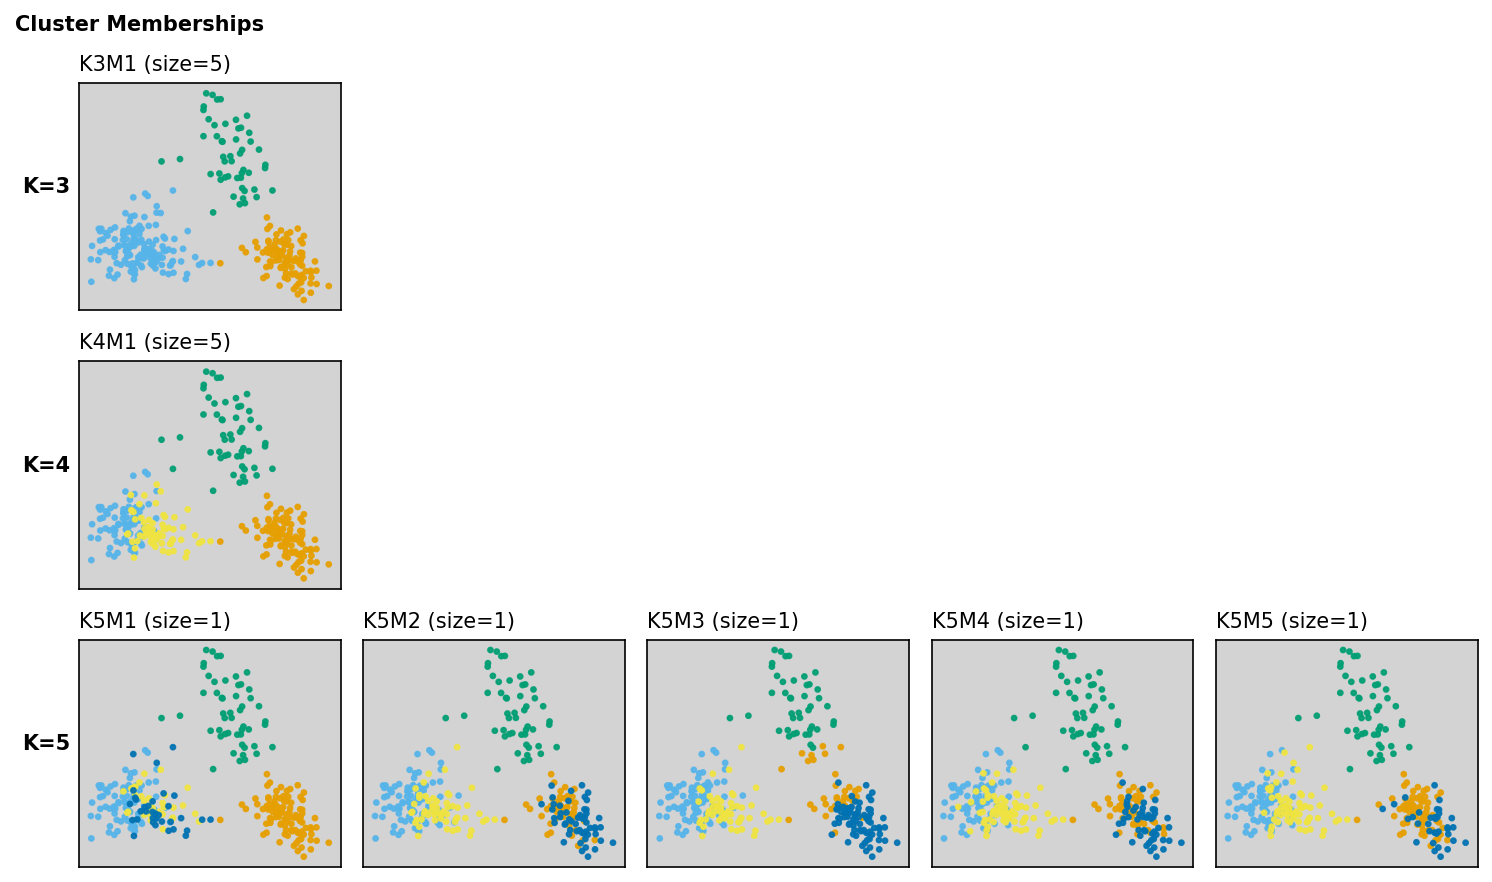

In [16]:
fig, axes = aoc.plot_cluster_overlay(
    results,
    coords=X_pca,
    cluster_colors=default_colors[:results.K_max],
    val_threshold=0.5,
    s=5,
    alpha=0.9,
    suptitle=f"Cluster Memberships",
    suptitle_kwargs= {'y':0.95, 'fontsize':10},
)

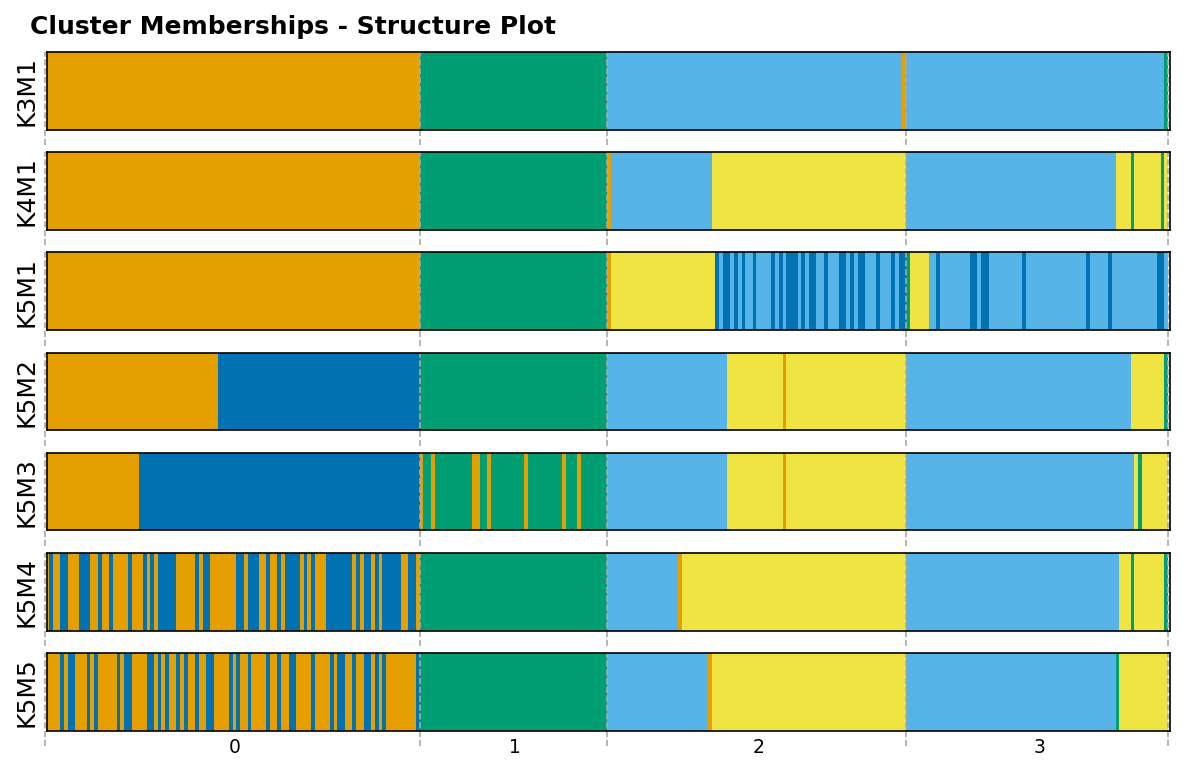

In [17]:
fig = aoc.plot_structure_one_level(
    results,
    cmap=default_colors,
    grp_labels=truth_labels,
    figsize=(8,5),
)
fig.suptitle("Cluster Memberships - Structure Plot", y=1.02, x=0.25, fontsize=12, weight='bold')
pass

## Model 2: NMF

In [18]:
align_dir = example_data_dir / "aligned" / "nmf"
cls_dir = example_data_dir / "clustering" / "nmf"

### Load Results

In [19]:
results = aoc.load_clumppling_results(
    align_dir=align_dir,
    suffix="rep",
    cls_dir=cls_dir,
    load_P=True,
    strict_P=True,   # raises FileNotFoundError if any P file is missing
)

# compute pairwise mappings between modes
pair_mappings = aoc.get_mode_pair_mappings(
    mode_names=results.modes,
    all_modes_alignment=results.all_modes_alignment,
    alignment_acrossK=results.alignment_acrossK,
)

In [20]:
results.mode_stats

,Mode,Representative,Size,Cost,Performance
0,K3M1,3_K3R3,5,1.590216e-14,1.000000
1,K4M1,10_K4R5,5,1.737760e-06,0.998863
2,K5M1,13_K5R3,5,3.120587e-05,0.994993


### Cluster Memberships

Q matrices of all modes.

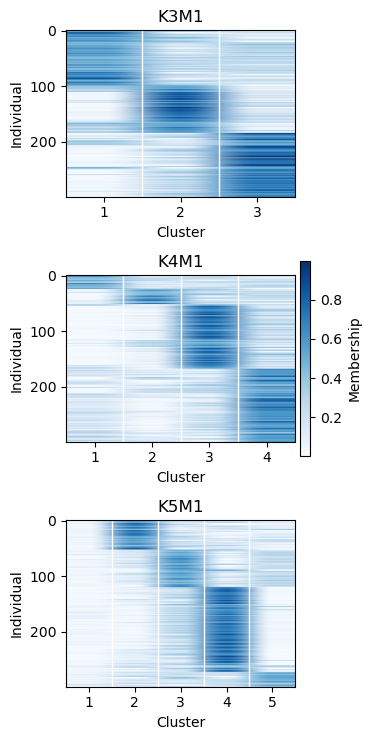

In [21]:
fig, axes = aoc.plot_Q_grid(results, cmap="Blues")
# if to visualize a single mode: aoc.plot_Q_heatmap(results, 'K3M1', cmap="Blues", ax=ax) 

Cluster sizes (sum of memberships) in one mode.

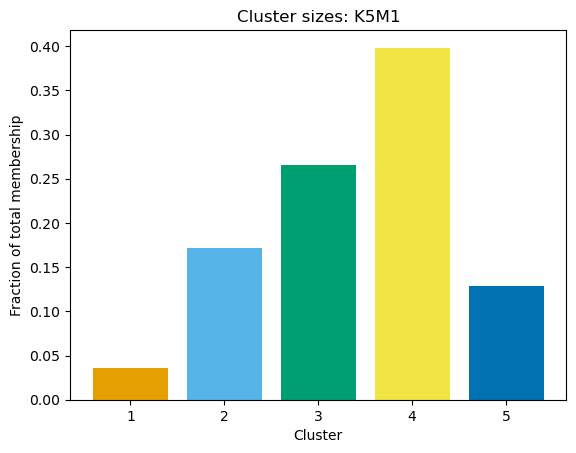

In [22]:
mode = 'K5M1'
fig, ax = aoc.plot_cluster_bars(results, mode, colors=default_colors[:results.mode_K[mode]])

All clusters in one scatter plot, showing points with membership above `val_threshold`.

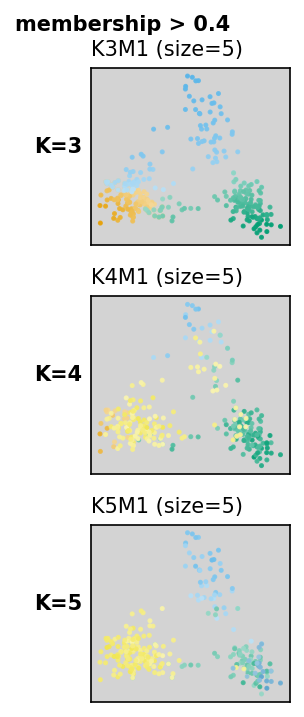

In [23]:
fig, axes = aoc.plot_cluster_overlay(
    results,
    coords=X_pca,
    cluster_colors=default_colors[:results.K_max],
    val_threshold=0.4,
    s=2,
    alpha=0.9,
    suptitle=f"membership > 0.4",
    suptitle_kwargs= {'y':0.92, 'fontsize':10},
    figsize=(2,5)
)

One panel per cluster.

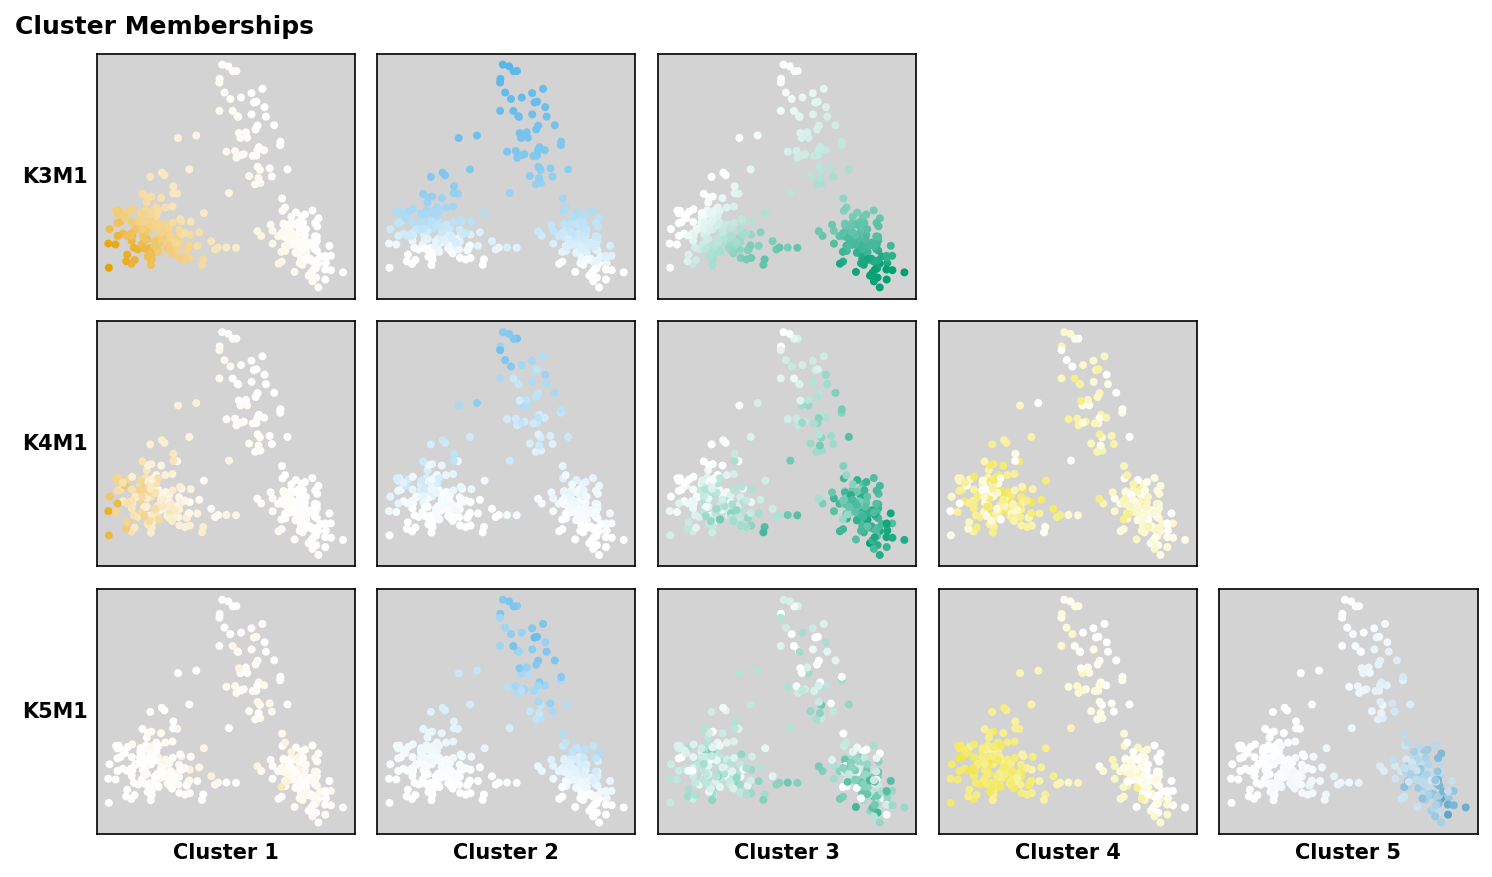

In [24]:
fig, axes = aoc.plot_cluster_panels(
    results,
    coords=X_pca,
    cluster_colors=default_colors[:results.K_max],    # or None → tab20 default
    val_threshold=-1,            # show all memberships
    s=8,
    alpha=1.0,
    suptitle="Cluster Memberships",
    suptitle_kwargs= {'y':0.94, 'fontsize':12},
)

One cluster in one mode.

Text(0.5, 1.0, 'K5M1, Cluster 1')

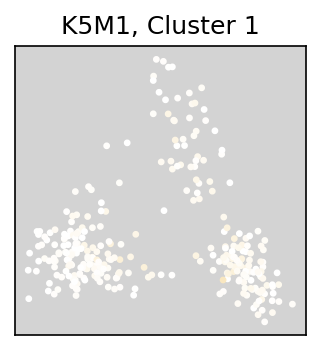

In [25]:
cluster_idx = 0  
Q = results.Q_by_mode[mode]      # shape (n_cells, K)
fig, ax = plt.subplots(1, 1, figsize=(2.5,2.5), dpi=150)
ax, sp = aoc.plot_spatial_membership(
    Q,
    X_pca,
    s=5, alpha=1.0,
    ref_color=default_colors[cluster_idx],   # base color for this cluster
    cls_idx=cluster_idx,
    ax=ax,
)
ax.set_title(f"{mode}, Cluster {cluster_idx + 1}")  # one-based in title


Structure plot of one mode.

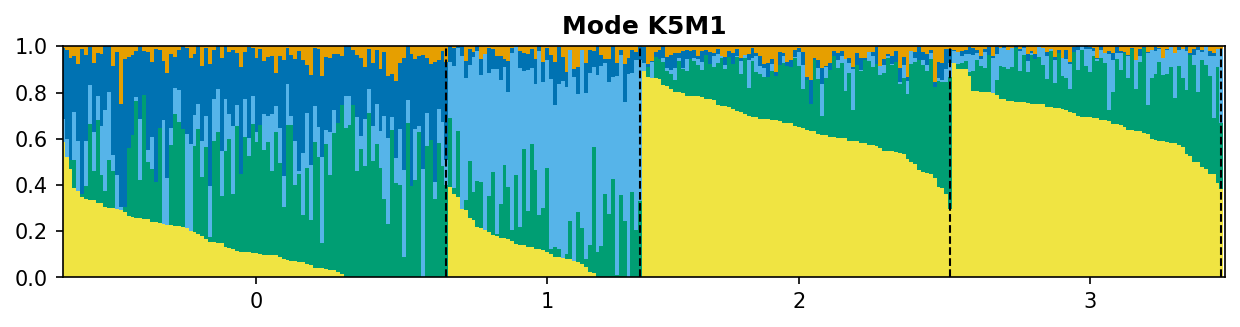

In [26]:
# plot a single membership (in structure bar charts)
fig, ax = plt.subplots(figsize=(10, 2), dpi=150)
# sort individuals within each label group by the largest cluster membership in that group
aoc.plot_membership_reordered(results.Q_by_mode[mode], cmap=default_colors[:results.mode_K[mode]], 
                                     lbs=truth_labels, ax=ax, title="", annot="")
# add vertical lines to separate groups
for sep in grp_seps:
    ax.axvline(x=sep - 0.5, color='black', linestyle='--', linewidth=1)
ax.set_xticks(grp_indices)
ax.set_xticklabels(grp_lbs)
ax.set_title(f"Mode { mode }", fontsize=12, weight='bold')
pass

Structure plots of all modes.

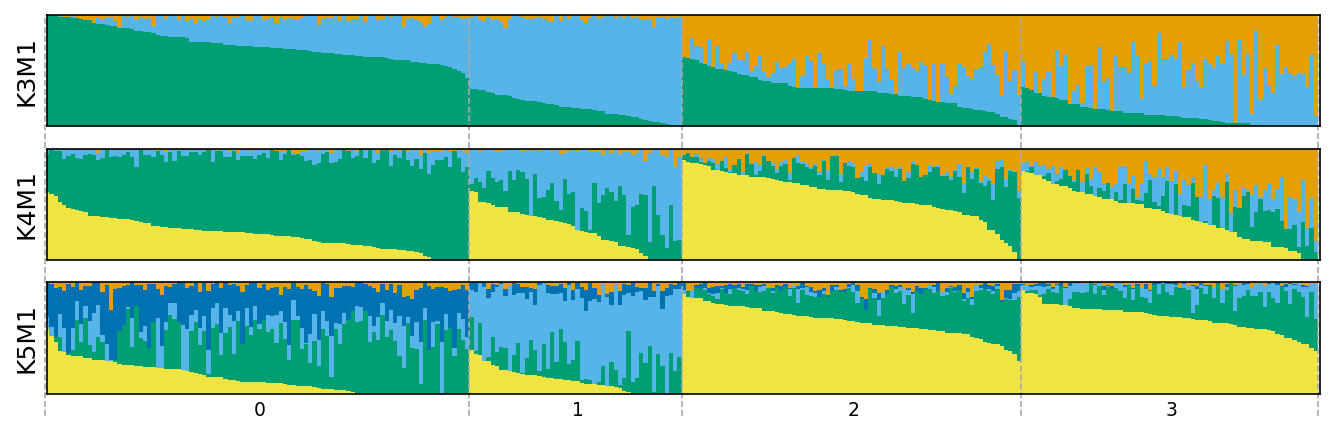

In [27]:
fig = aoc.plot_structure_one_level(
    results,
    cmap=default_colors[:results.K_max],
    grp_labels=truth_labels,
    lb_suffix_sep="_",
    reorder_clsind=True,
)

### Alignment Graph

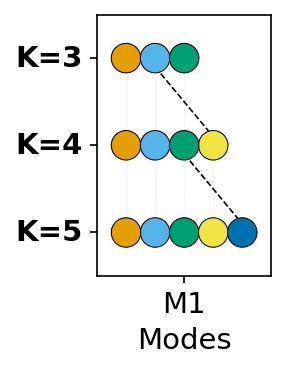

In [28]:
from clumppling.plot import plot_alignment_graph

fig = plot_alignment_graph(results.K_range, names_list=results.mode_names_list, cmap=default_colors[:results.K_max], 
                           alignment_acrossK=results.alignment_acrossK, all_modes_alignment=results.all_modes_alignment,
                           alt_color=False, ls_alt=['-', '--'])

### Subset of Modes

`subset_results` returns a new `ClumpplingResults` with only the selected modes; all plots above work on it.

In [29]:
modes_subset = ['K3M1', 'K4M1']
sub = aoc.subset_results(results, modes_subset)

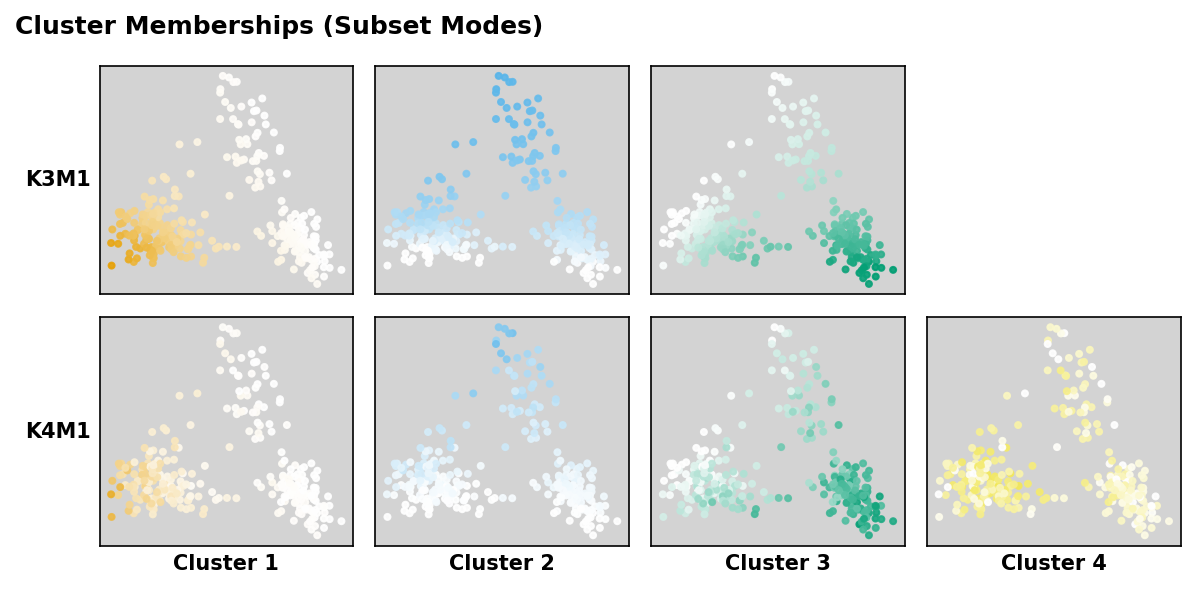

In [30]:
fig, axes = aoc.plot_cluster_panels(
    sub,
    coords=X_pca,
    cluster_colors=default_colors[:sub.K_max],    # or None → tab20 default
    val_threshold=-1,            
    s=8,
    alpha=0.9,
    suptitle="Cluster Memberships (Subset Modes)",
    suptitle_kwargs= {'y':0.93, 'fontsize':12},
)

Scatter and structure plots together.

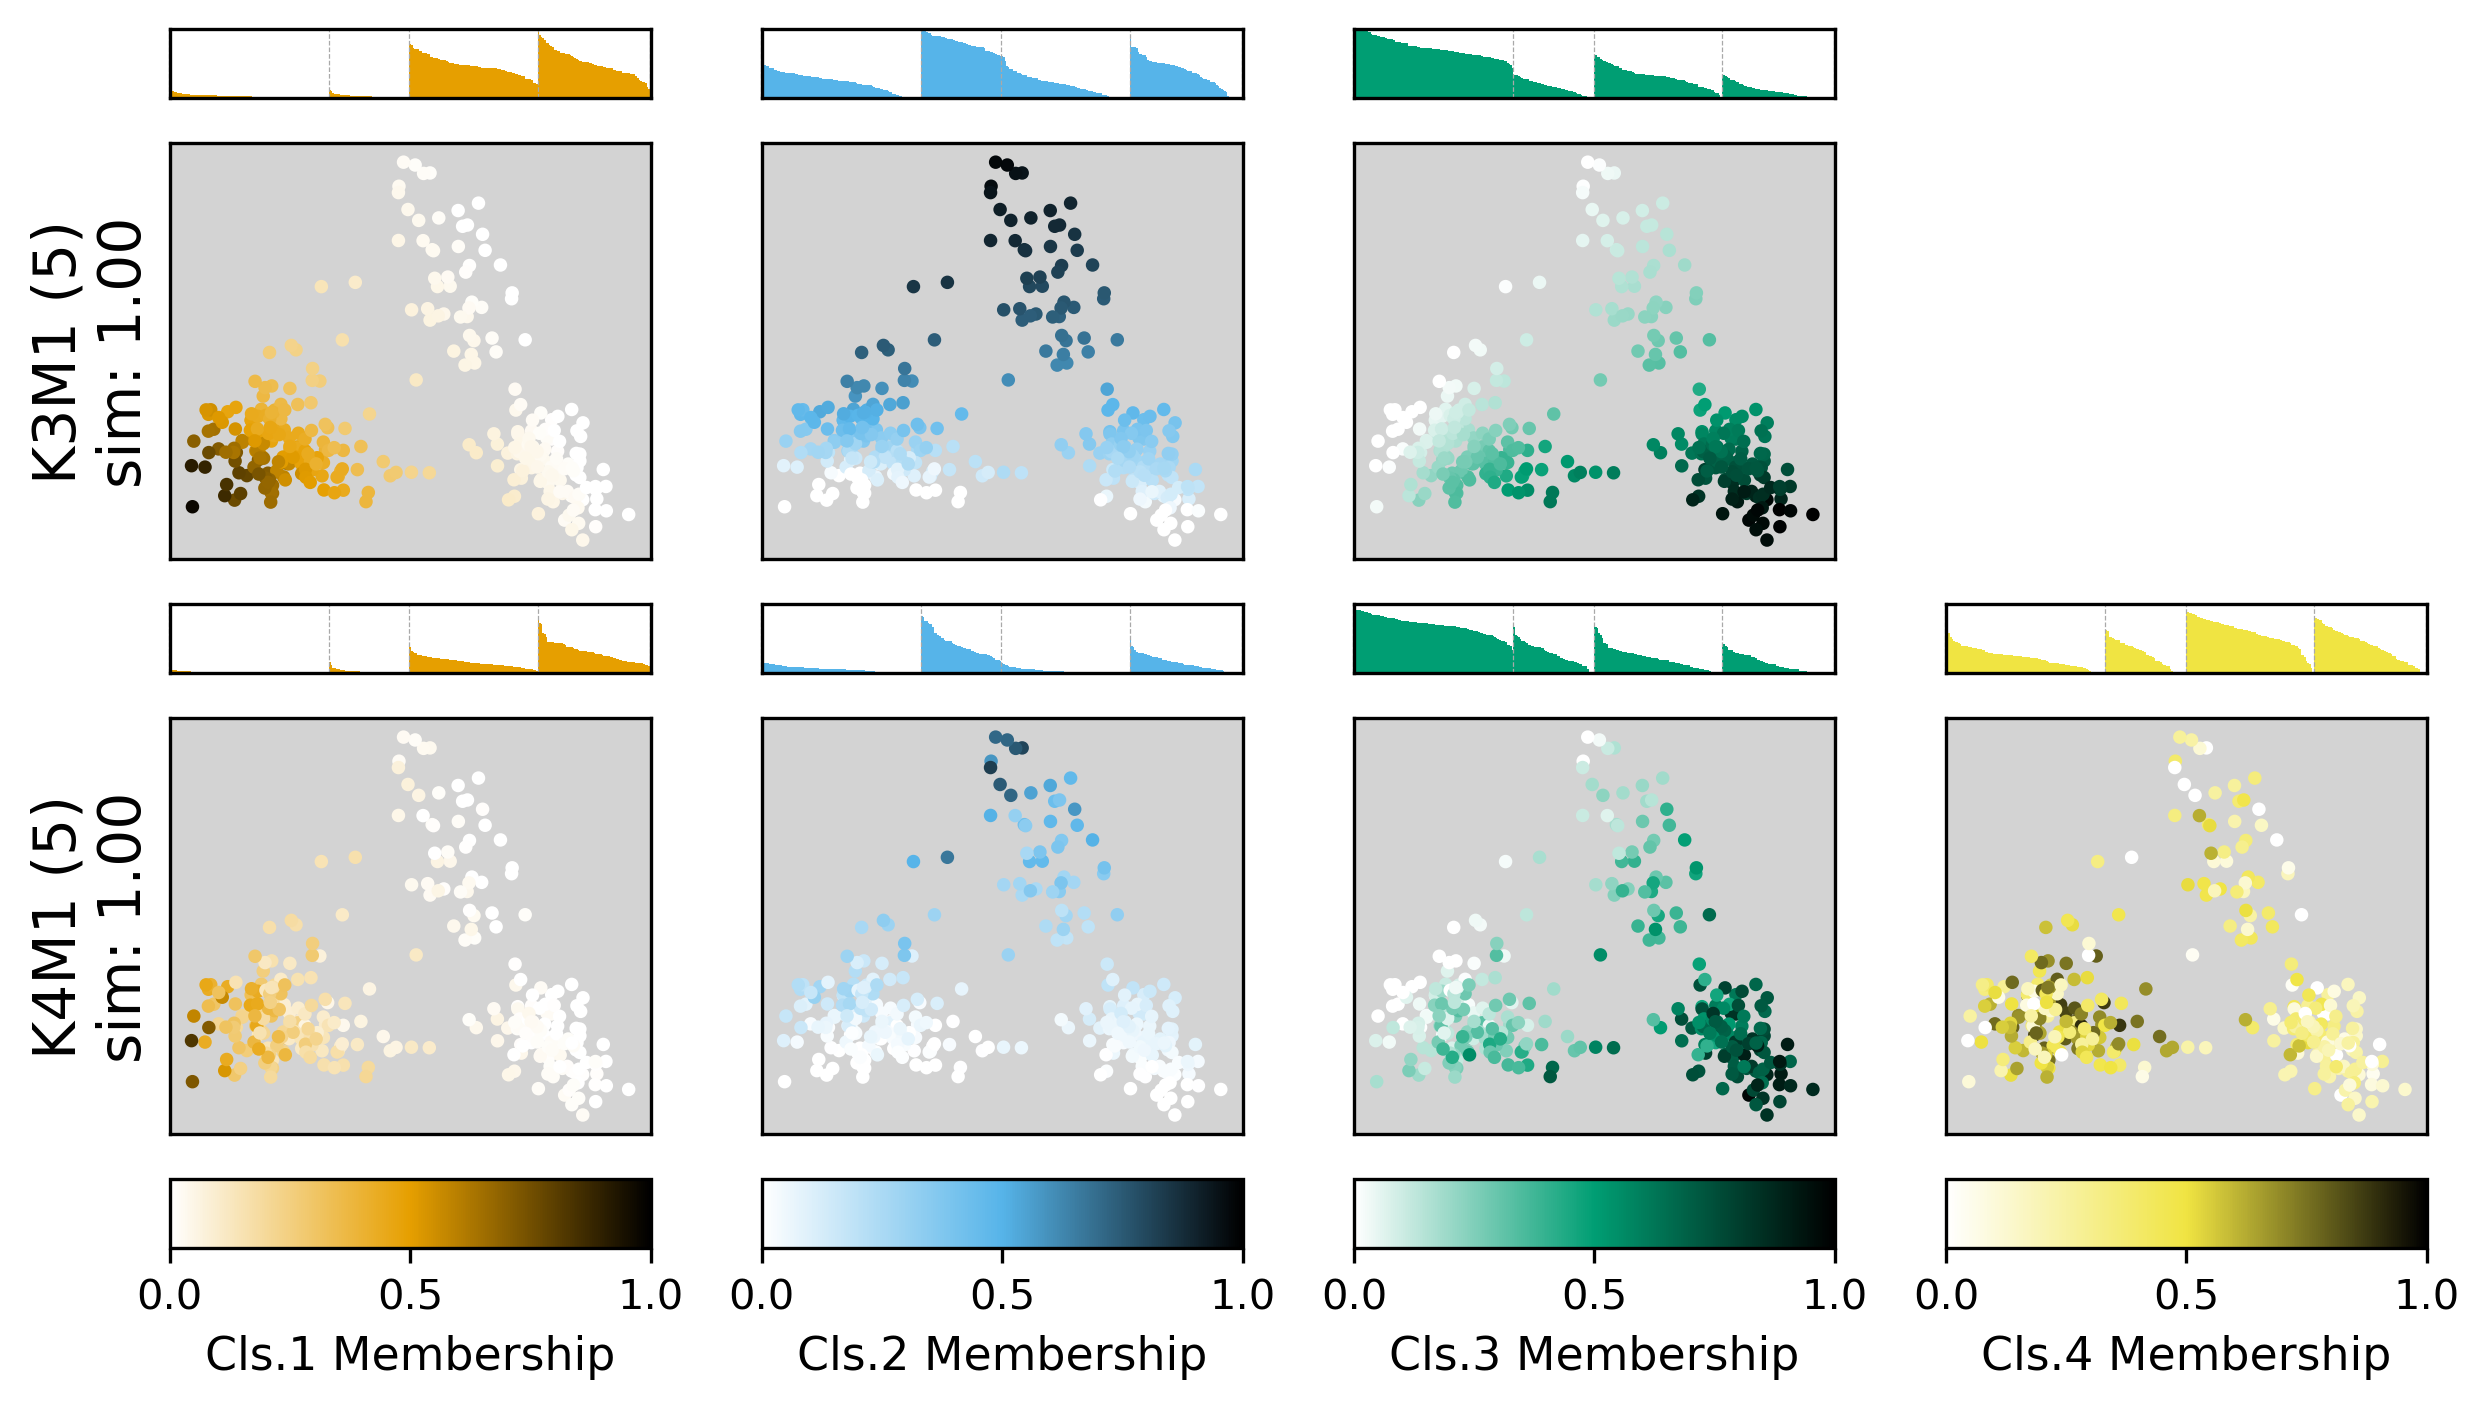

In [31]:
fig = aoc.plot_spatial_structure_grid(
    sub,
    X_pca,
    grps=truth_labels,
    cmap=default_colors[:sub.K_max],
    s=5,
    dpi=300,
)

### Feature Analysis

For mixed-membership clustering only. Each mode's P matrix ($G \times K$ for $G$ features) gives two metrics per feature:
- **weighted_Psum**: overall contribution of the feature, weighted by cluster size
- **sepLFC**: largest log2 gap between the feature's sorted cluster P values (cluster specificity)

In [32]:
df_by_mode = aoc.compute_all_feature_metrics(results, feature_names=feature_names)

# select top features by weighted_Psum quantile across all modes 
selected_by_mode, df_selected_all, overlap = aoc.select_top_features(
    df_by_mode,
    top_quantile=0.5,
)


Metrics for one mode.

In [33]:
df_by_mode['K4M1'].head()

,weighted_Psum,sepLFC,sepCls
Feature1,0.005905,37.733877,"((3,), (0, 1, 2))"
Feature2,0.005582,3.805409,"((1,), (0, 3, 2))"
Feature3,0.003793,39.000536,"((2,), (3, 1, 0))"
Feature4,0.007891,38.915322,"((3,), (0, 1, 2))"
Feature5,0.001886,36.057279,"((3,), (2, 1, 0))"


`weighted_Psum` vs. `sepLFC` (set `x` and `y` for other columns), with selected features highlighted.

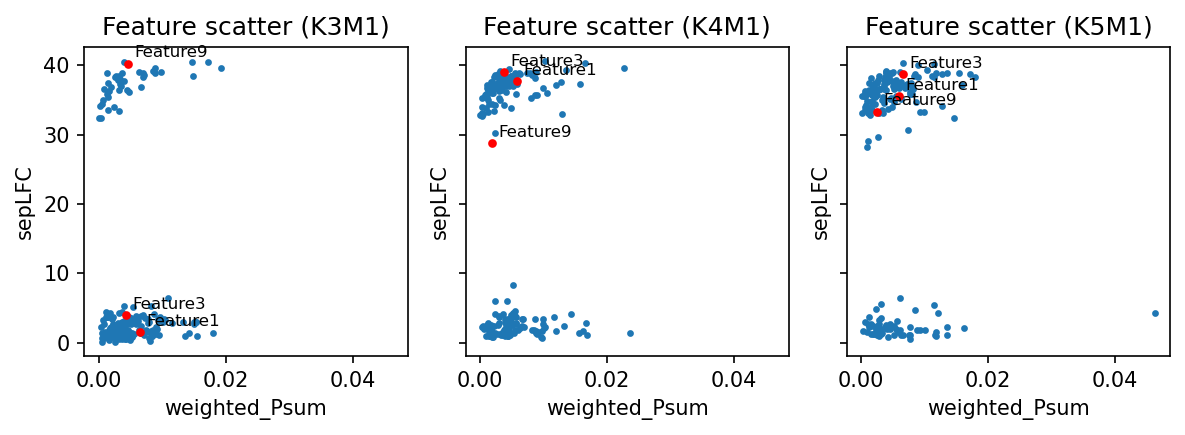

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(8,3), dpi=150, sharex=True, sharey=True)
aoc.plot_feature_scatter(df_by_mode['K3M1'], mode_name='K3M1', 
                                   ax=axes[0], highlight=['Feature1', 'Feature3', 'Feature9'])
aoc.plot_feature_scatter(df_by_mode['K4M1'], mode_name='K4M1', 
                                   ax=axes[1], highlight=['Feature1', 'Feature3', 'Feature9'])
aoc.plot_feature_scatter(df_by_mode['K5M1'], mode_name='K5M1', 
                                   ax=axes[2], highlight=['Feature1', 'Feature3', 'Feature9'])
fig.tight_layout()
pass

Top features by a metric (default `weighted_Psum`).

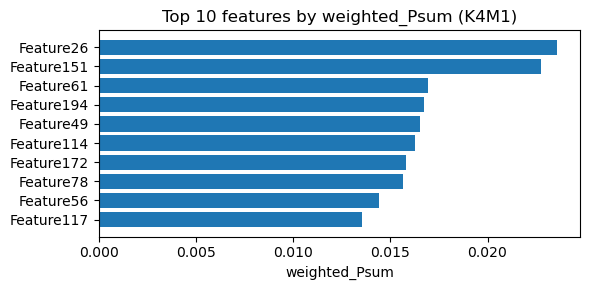

In [35]:
fig, ax = aoc.plot_feature_bar(df_by_mode['K4M1'], mode_name='K4M1', top_n=10)

Clustering-informative candidates: outliers of the joint KDE of the two metrics.

In [36]:
mode = 'K4M1'
outliers_features, outliers_mask = aoc.get_kde_outliers(
    df_by_mode[mode],
    x_col=f"weighted_Psum",
    y_col=f"sepLFC",
    levels=8,
    min_x=0.0,
    return_mask=True,
    cut=0,
)
print("Number of outliers detected:", len(outliers_features))
outliers_features

Number of outliers detected: 5


,weighted_Psum,sepLFC,sepCls
Feature26,0.023579,1.394149,"((0,), (1, 2, 3))"
Feature49,0.016508,40.293818,"((0,), (3, 1, 2))"
Feature119,0.009842,0.712435,"((1, 0, 2), (3,))"
Feature151,0.022758,39.628920,"((1,), (0, 3, 2))"
Feature172,0.015819,37.345073,"((0,), (3, 1, 2))"


Number of outliers with sepLFC>1: 4


Text(25.58333333333333, 0.5, 'sepLFC')

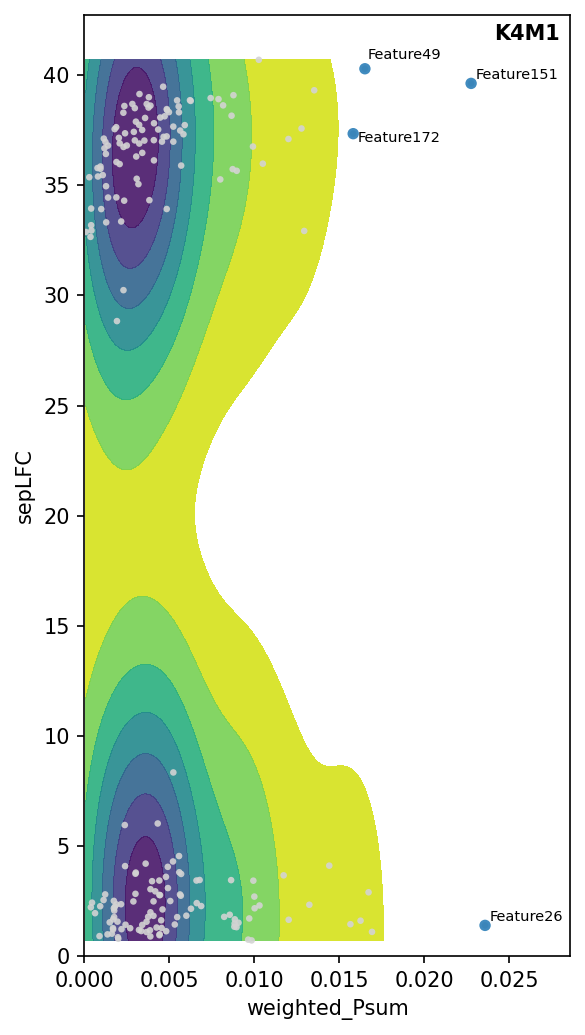

In [37]:
outliers_mask &= (selected_by_mode[mode][f"sepLFC_{mode}"]>1)
print(f"Number of outliers with sepLFC>1: {np.sum(outliers_mask)}")
fig, ax = aoc.plot_feature_kde(
    df_by_mode[mode],
    x_col=f"weighted_Psum",
    y_col=f"sepLFC",
    mode_name=mode,
    levels=8,
    outlier_mask=outliers_mask,
    bg_alpha=0.9,
)
ax.set_xlabel("weighted_Psum")
ax.set_ylabel("sepLFC")


Top features for all modes.

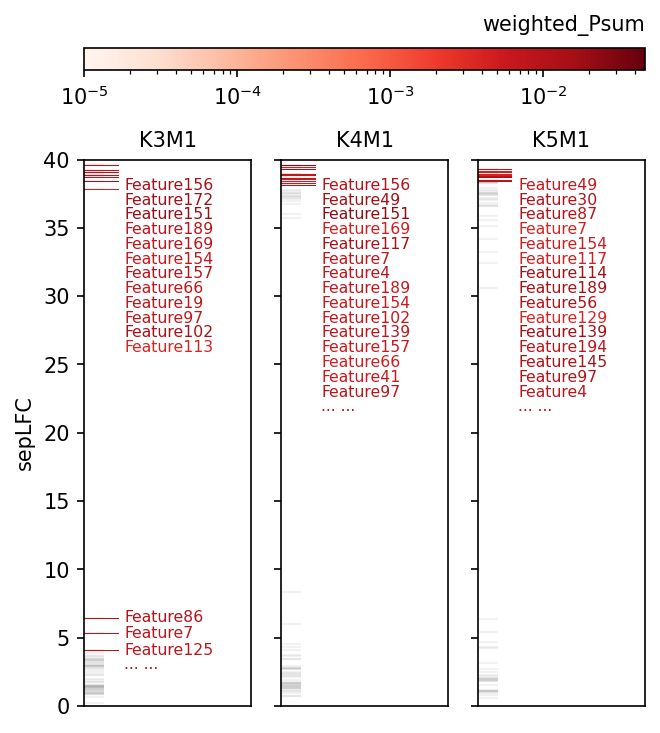

In [38]:
modes = results.modes  # or a subset like ["K21M1", "K25M2", ...]

fig, axes_by_mode = aoc.plot_sepLFC_labels(
    df_selected_all,
    modes,
    sepLFC_threshold=0.0,
    figsize_scale=1.5,
    n_top_lo=5,
)

### Focal Feature

Add gray for features that separate multiple clusters.

In [39]:
custom_palette = {'Cls.{}'.format(i_c+1):c for i_c,c in enumerate(default_colors[:results.K_max])}
custom_palette['Multi.Cls'] = '#A9A9A9'

Metrics of the focal feature across modes.

2026-11-05 14:40:35 - WARNING  Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


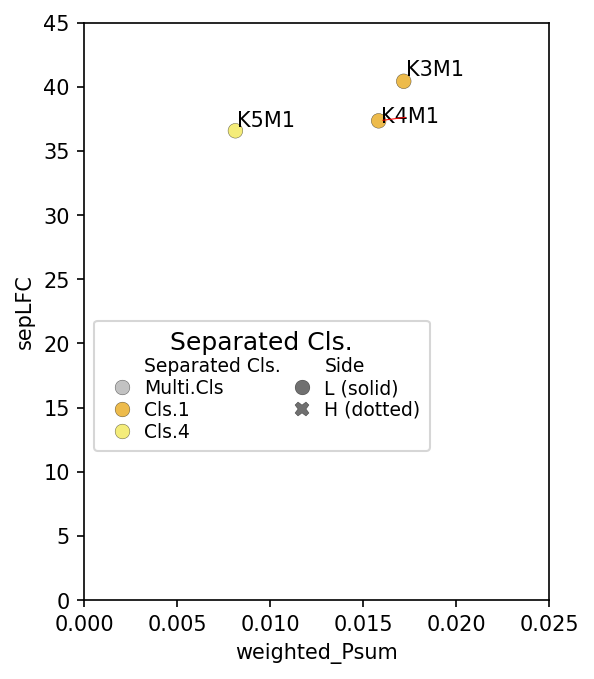

In [40]:
focal_feature = "Feature172"
modes = results.modes

fig, ax = plt.subplots(figsize=(4,5), dpi=150)
_, _, df_gene = aoc.plot_feature_across_modes(
    df_pvs_modes=df_by_mode,
    modes=modes,
    selected_feature=focal_feature,
    custom_color_dict=custom_palette,
    xlim=[0.0, 0.025],
    ylim=[45],
    legend_loc="upper left",
    legend_bbox_to_anchor=(0.0, 0.5),
    ax=ax
)

Clusters it separates.

Text(0.5, 0.95, 'Separated clusters')

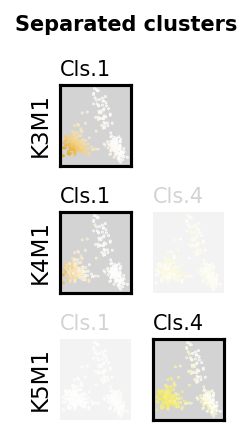

In [41]:
fig, axes = aoc.plot_feature_cluster_panels(
    results=results,      
    coords=X_pca,
    df_pvs_modes=df_by_mode,
    selected_feature=focal_feature,
    modes=modes,                 
    colors=default_colors,          
    plot_both_sides=False,       
    val_threshold=0.0,
    w_scale=0.8, h_scale=1.0,
)
fig.suptitle("Separated clusters", fontsize=10, weight='bold', y=0.95)

Both sides of the separation.

Text(0.5, 0.97, 'Separated clusters for Gene Feature172')

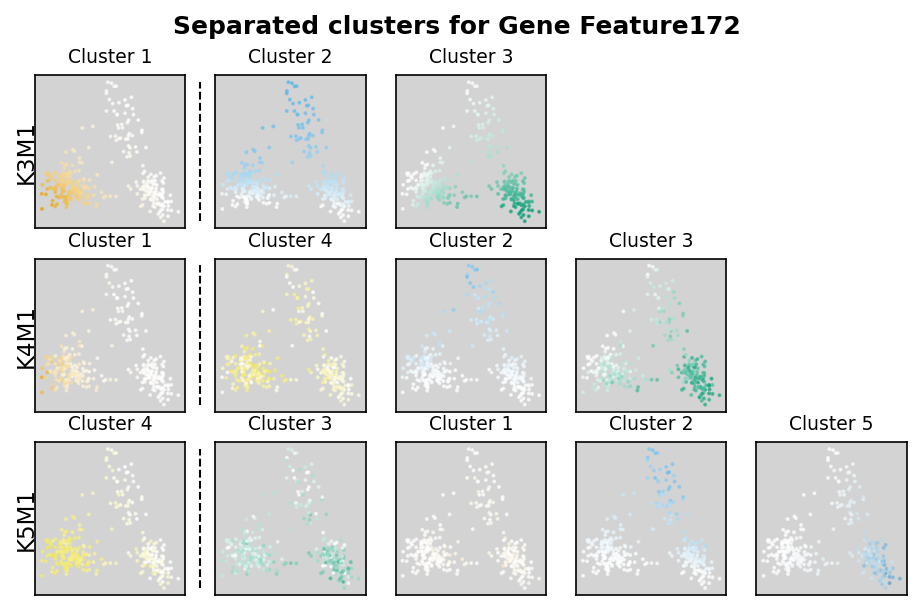

In [42]:
fig, axes = aoc.plot_feature_cluster_panels(
    results=results,      
    coords=X_pca,
    df_pvs_modes=df_by_mode,
    selected_feature=focal_feature,
    modes=modes,                 
    colors=default_colors,         
    plot_both_sides=True,       
    val_threshold=0.0,
    h_scale=1.5,
    w_scale=1.5,
)
fig.suptitle(f"Separated clusters for Gene {focal_feature}", y=0.97, fontsize=12, weight='bold')



Its feature values.

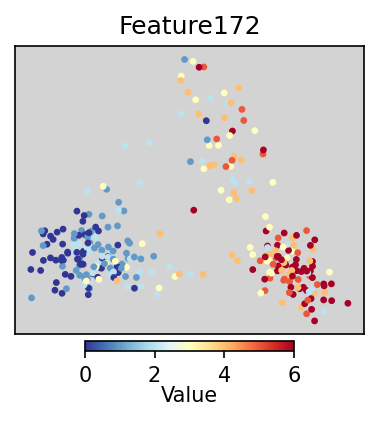

In [43]:
i_g = feature_names.index(focal_feature)
feature_val = truth_X[:, i_g]
fig, ax = plt.subplots(1, 1, figsize=(3,3), dpi=150)
fig = aoc.plot_feature_count(feature_val, X_pca, feature_name=feature_names[i_g], ax=ax,
                             cmap="RdYlBu_r", cbar_label="Value")

## Multi-Model Comparison

In [44]:
comp_res = aoc.load_compmodels_results(
    res_dir=model_comp_output_dir,
    input_dir=model_comp_dir,
)

# Extract mode-pair mappings across all models
pair_mappings = aoc.get_mode_pair_mappings(
    mode_names=comp_res.full_mode_names,
    all_modes_alignment=comp_res.all_modes_alignment,
    alignment_acrossK=comp_res.alignment_across_all,
)

# Display names of all modes
print(f"Loaded {len(comp_res.full_mode_names)} aligned modes from {len(comp_res.models)} models.")
models = comp_res.models
for model in models:
    print(f" Model: {model}")
    print("\t", comp_res.modes_by_model[model])

[load_compmodels_results] Warning: mode_stats file not found for model 'ground.truth': examples/data/toy/comp_models/toy/ground.truth_mode_stats.txt
Loaded 14 aligned modes from 4 models.
 Model: ground.truth
	 ['ground.truth']
 Model: kmeans
	 ['K3M1', 'K4M1', 'K5M1', 'K5M2', 'K5M3', 'K5M4', 'K5M5']
 Model: lda
	 ['K3M1', 'K4M1', 'K5M1']
 Model: nmf
	 ['K3M1', 'K4M1', 'K5M1']


### Cluster Memberships

Only points with membership above `val_threshold` are shown. For hard clustering any value in (0, 1) works; for mixed membership, 0.1–0.5 is a good range.

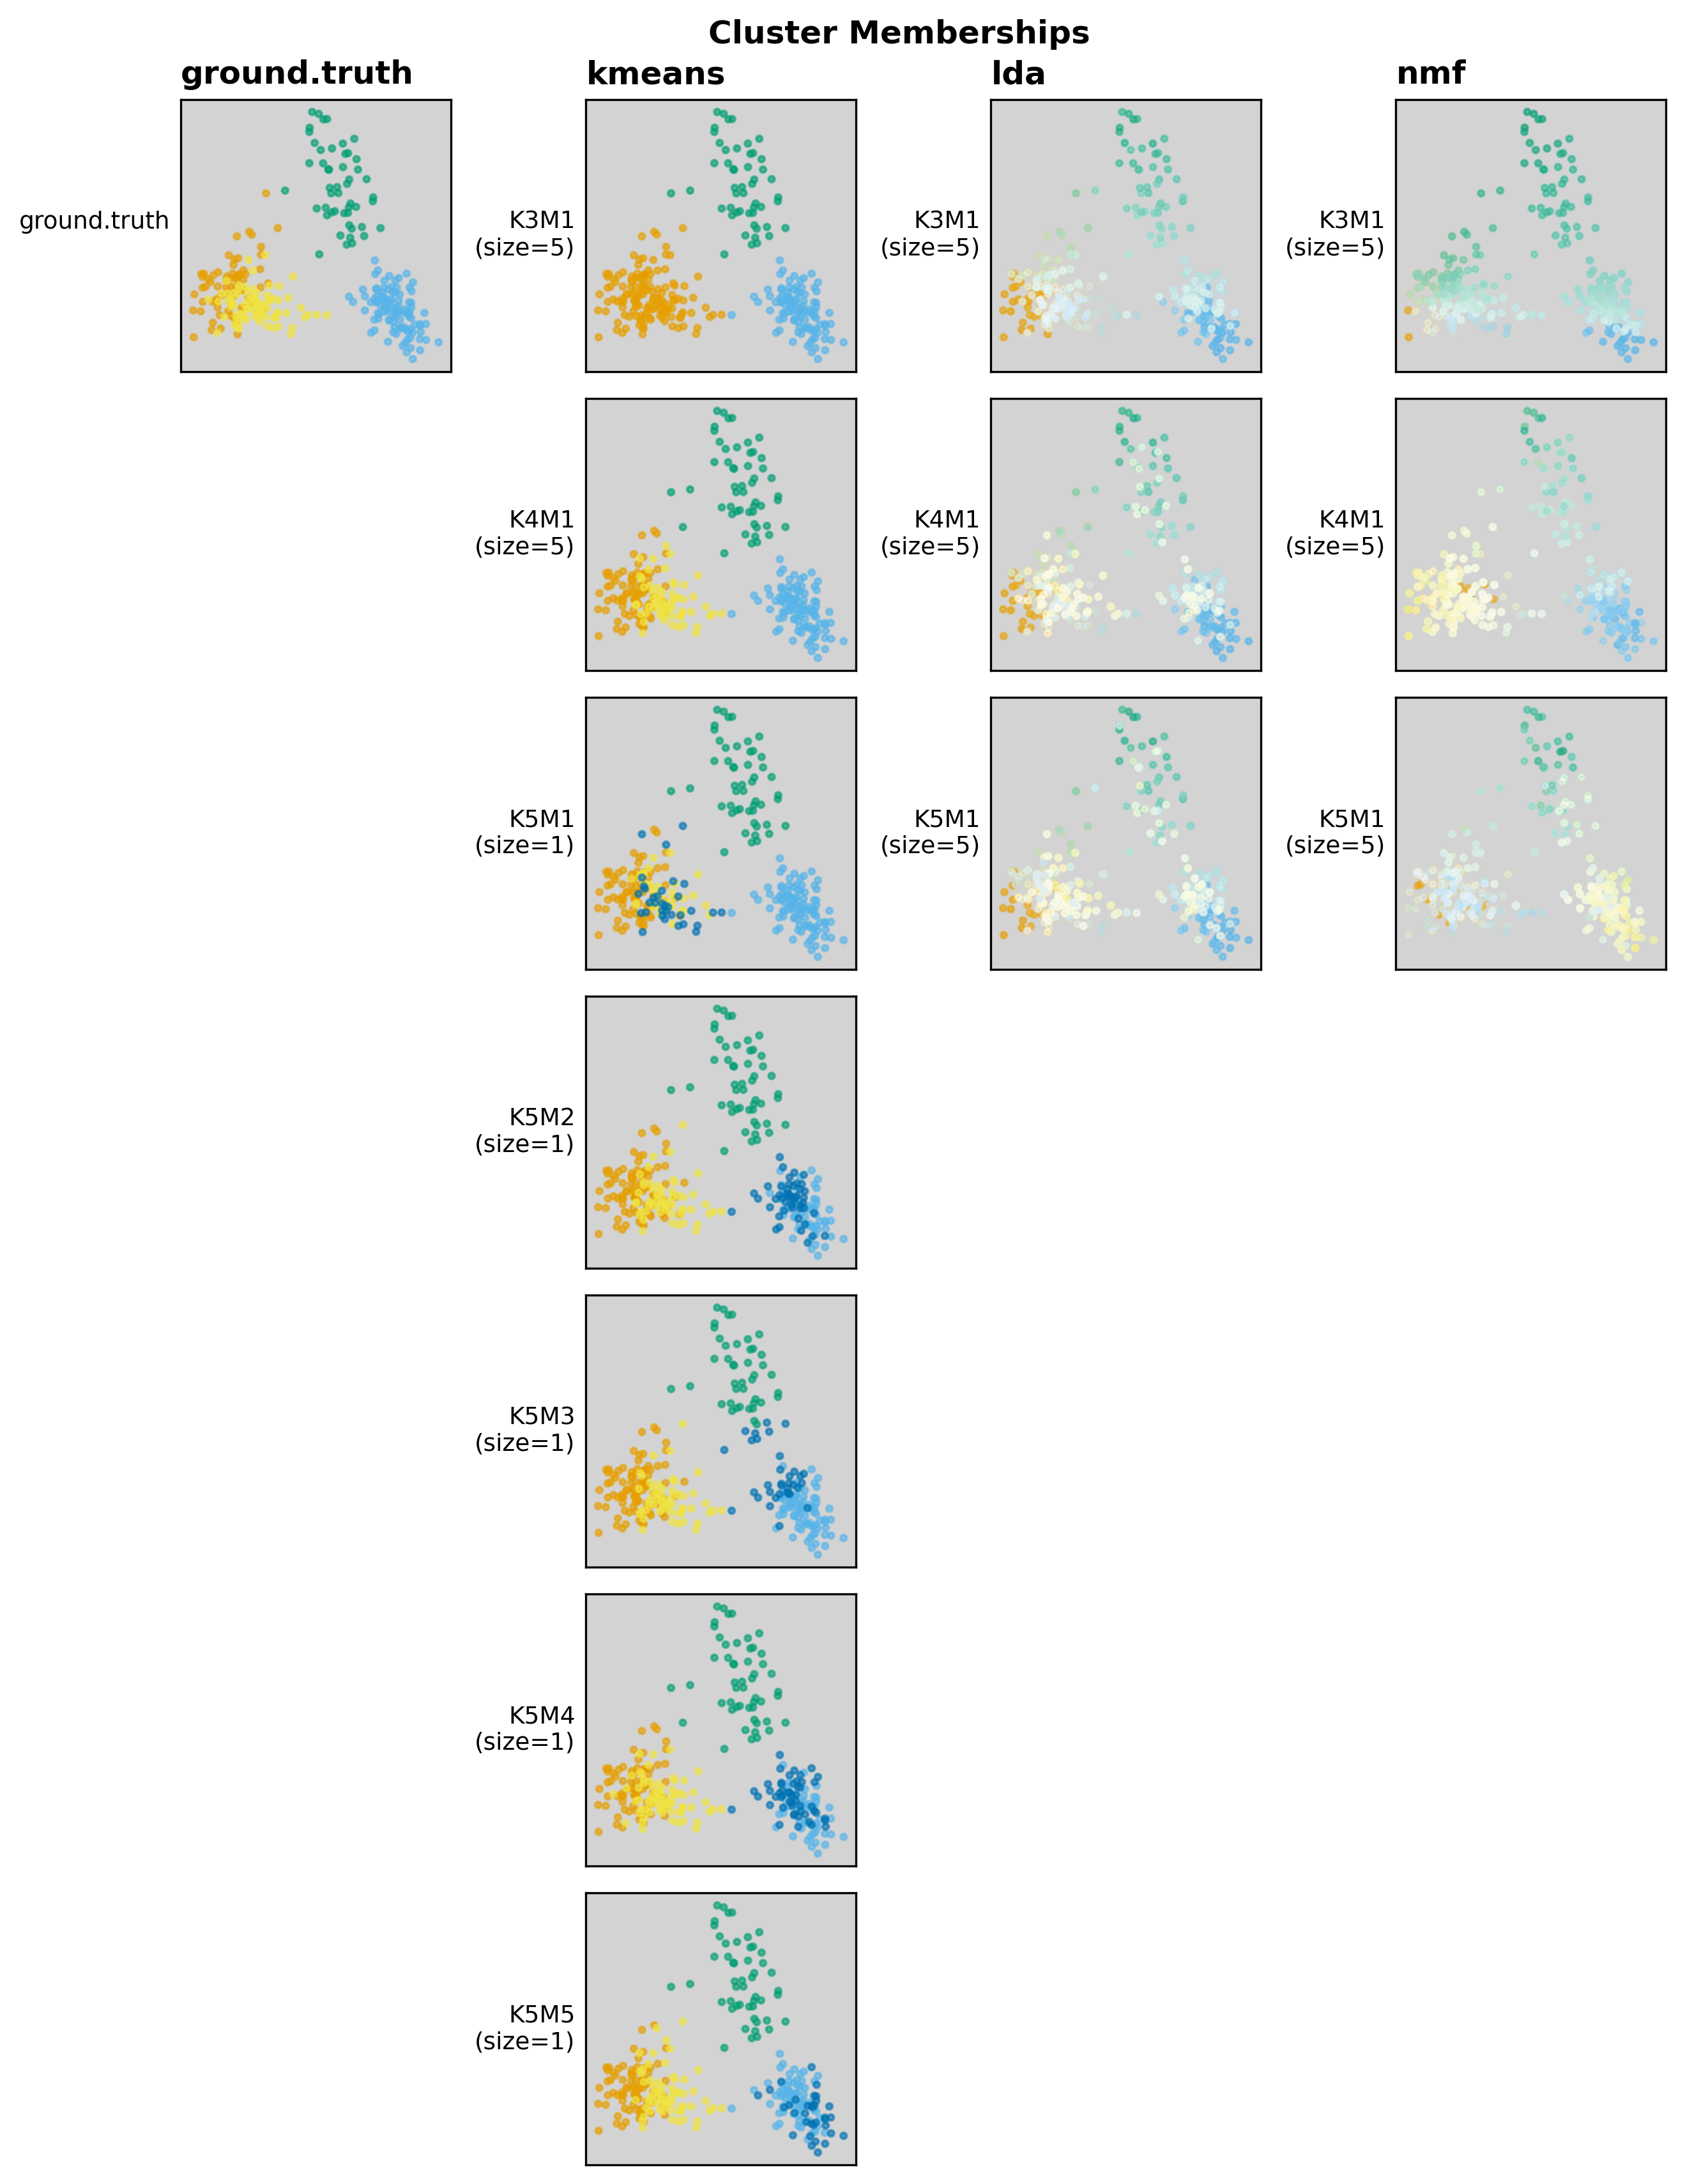

In [45]:
fig, ax = aoc.plot_compmodels_Q_grid(
    comp_res,
    X_pca, # coordinates for scatter plot
    colors=default_colors[:comp_res.K_max],
    val_threshold=0.1, # only plot points with membership values above this threshold
    suptitle="Cluster Memberships",
    y_suptitle=0.91,
    s=5, 
    models_plot_order=models,
)

Points that differ from `ref_mode` by more than `diff_threshold`.

Comparing to ground.truth_ground.truth


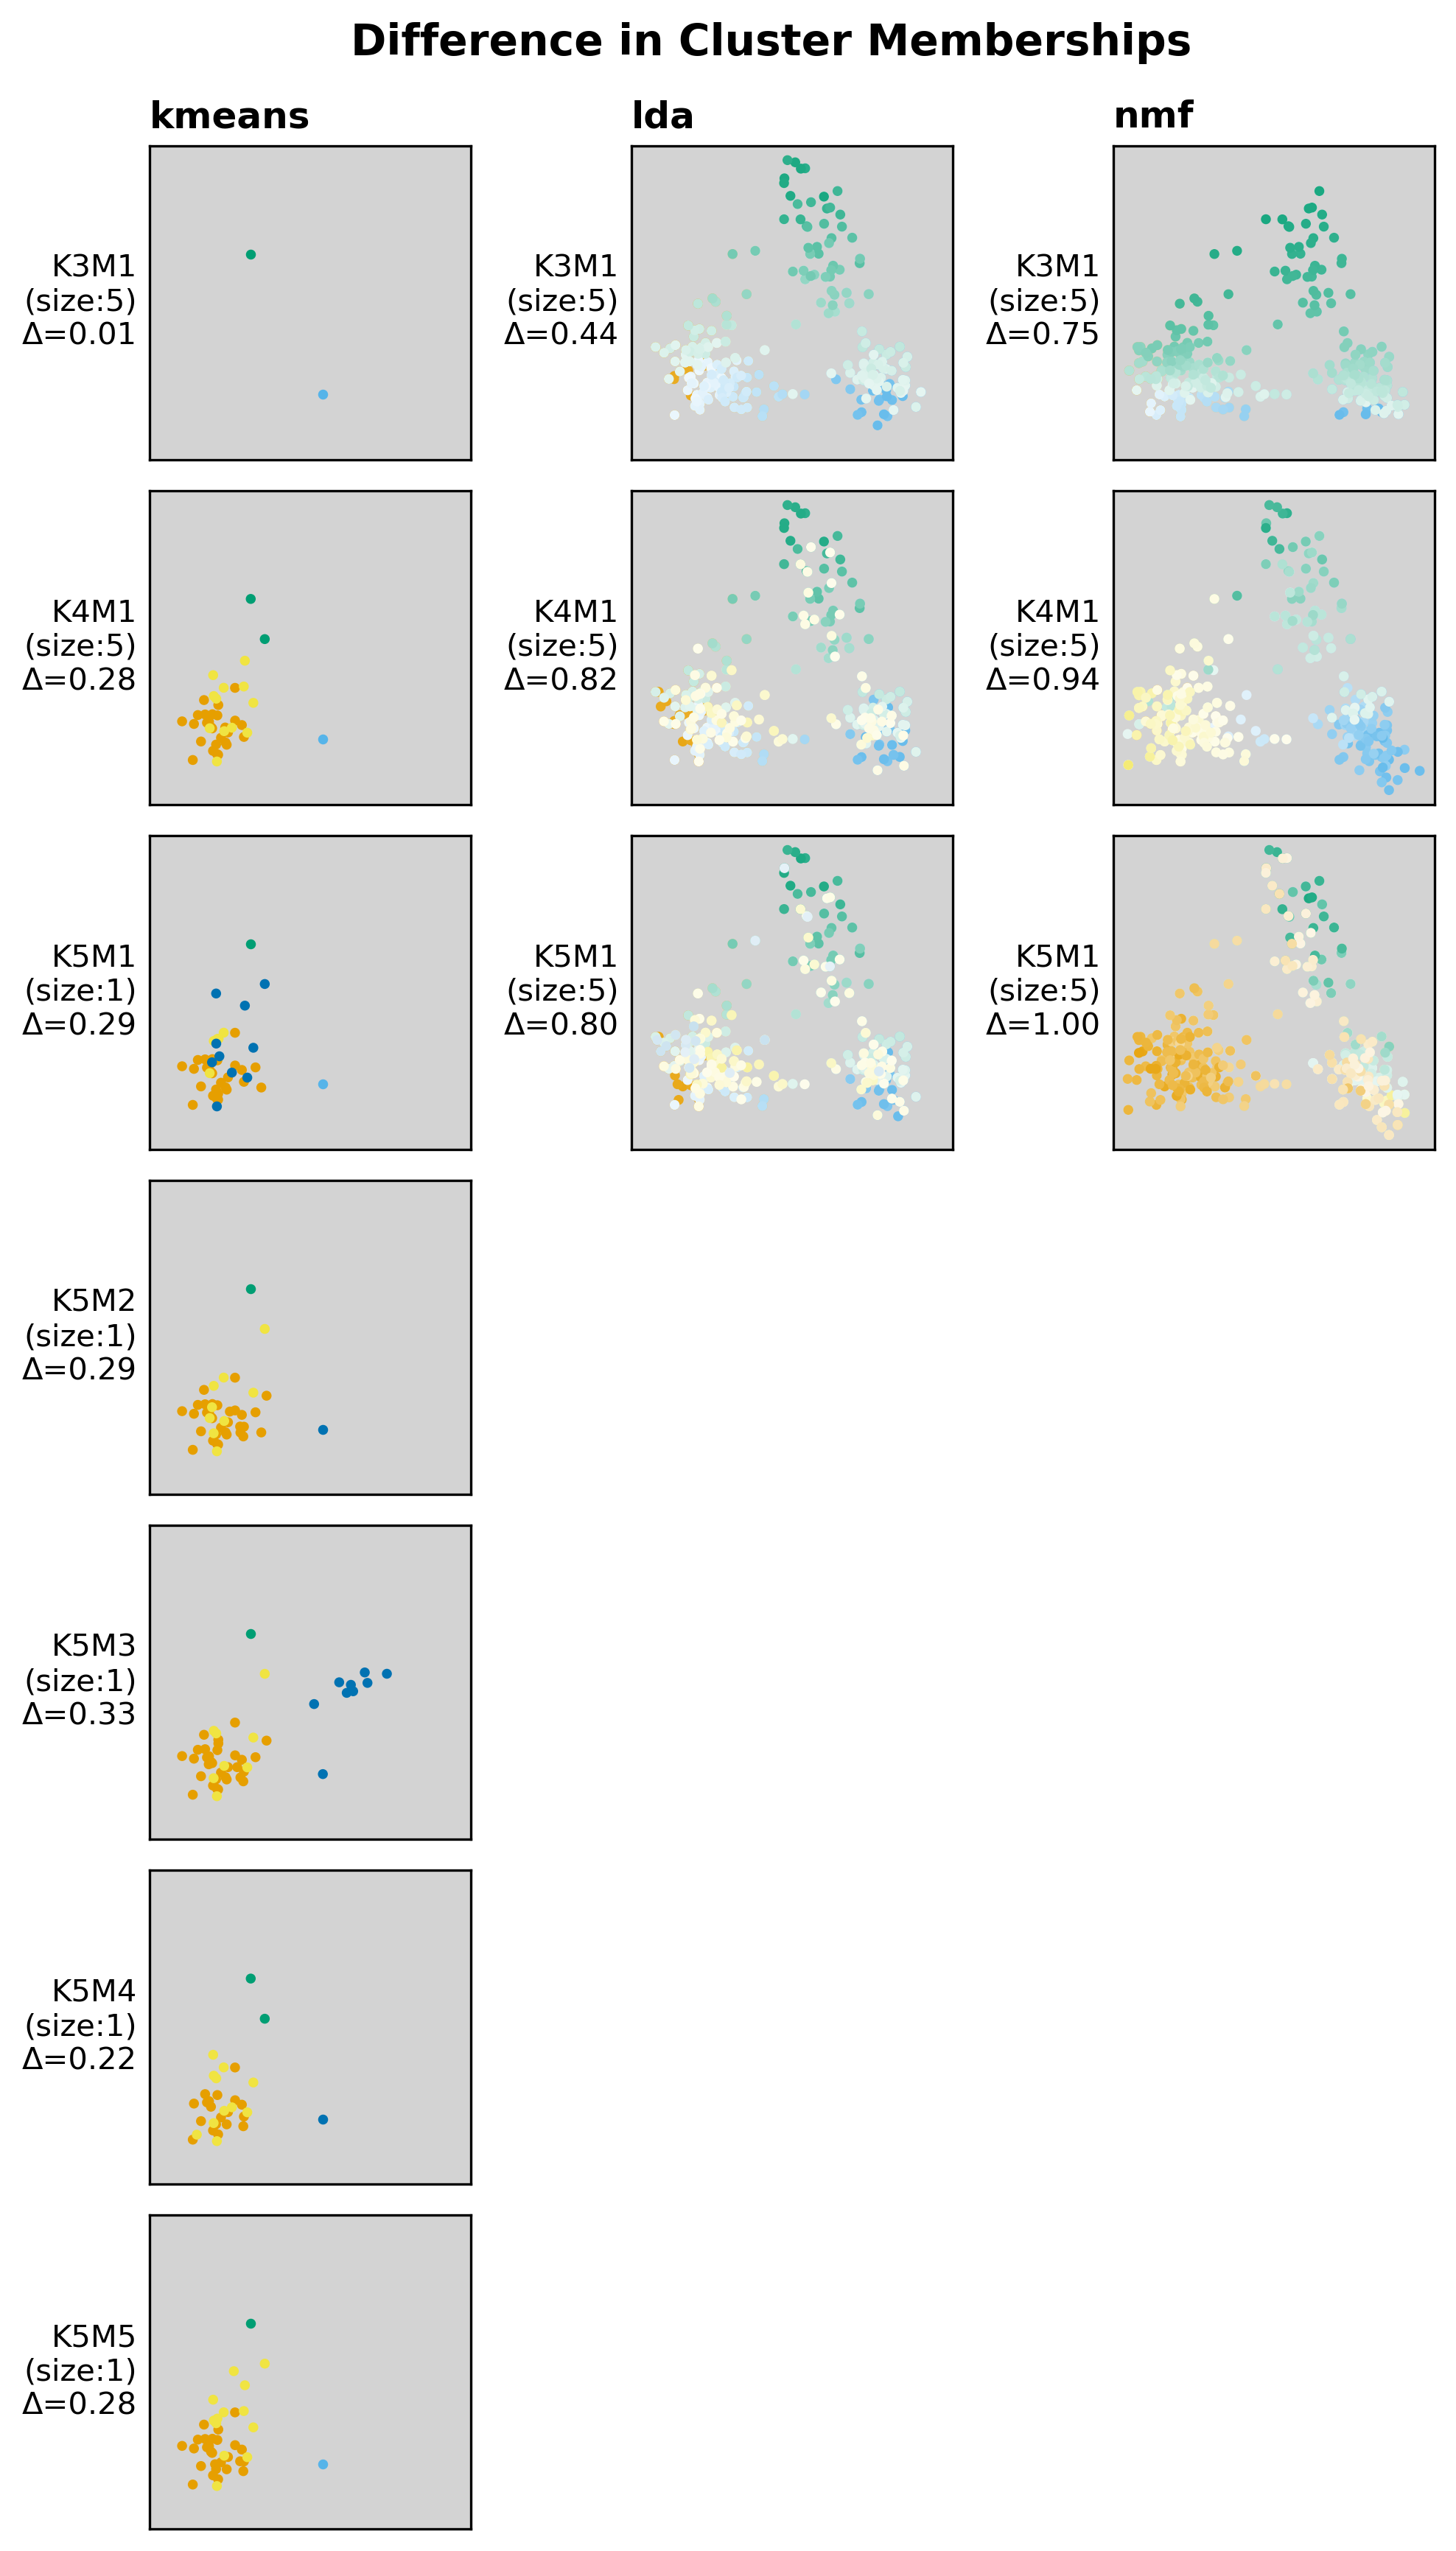

In [46]:
ref_mode = "ground.truth_ground.truth"
print(f"Comparing to {ref_mode}")

fig_diff, axes_diff = aoc.plot_compmodels_diff_grid(
    comp_res=comp_res,
    pair_mappings=pair_mappings,
    coords=X_pca,
    ref_mode=ref_mode, # the full name of the reference mode to compare to
    models_plot_order=models[1:],  # exclude ground truth from the diff plots
    diff_threshold=0.1, # only plot points with differences above this threshold
    val_threshold=0.1, # only plot points with reference membership values above this threshold
    colors=default_colors[:comp_res.K_max],
    s=5, alpha=0.9,  # point size and transparency
    suptitle="Difference in Cluster Memberships",
    y_suptitle=0.92,
)

Major modes only (the mode with the most runs in each model).

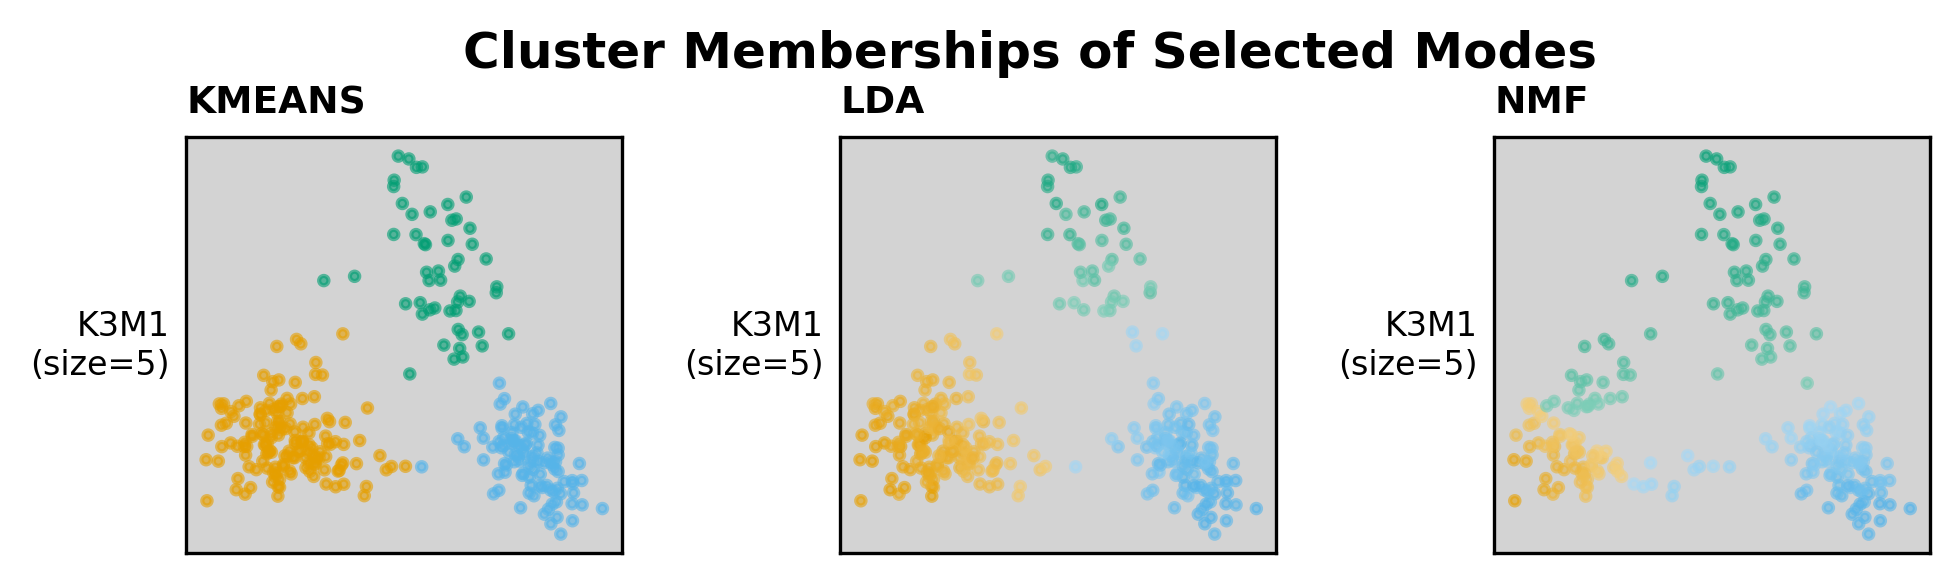

In [47]:
# get the major mode (with largest size) from each model
modes_to_plot = list()
for model in models[1:]:  # skip ground truth
    major_mode = comp_res.mode_stats_by_model[model].sort_values(by='Size', ascending=False).index.values[0]
    modes_to_plot.append((model, major_mode))

fig, axes = aoc.plot_compmodels_Q_selected(
    comp_res,
    X_pca,
    model_mode_list=modes_to_plot,
    n_rows=1,          # number of rows in the plot grid
    colors=default_colors,  
    suptitle="Cluster Memberships of Selected Modes",
    y_suptitle=1.08,
    figsize_scale=(2.5,1.8),
    s=5,
)
# update individual titles
for model, mode in modes_to_plot:
    axes[(model, mode)].set_title(model.upper(), fontsize=9, weight='bold', loc='left')

### Alignment Across Models

(-5.0, 26.5)

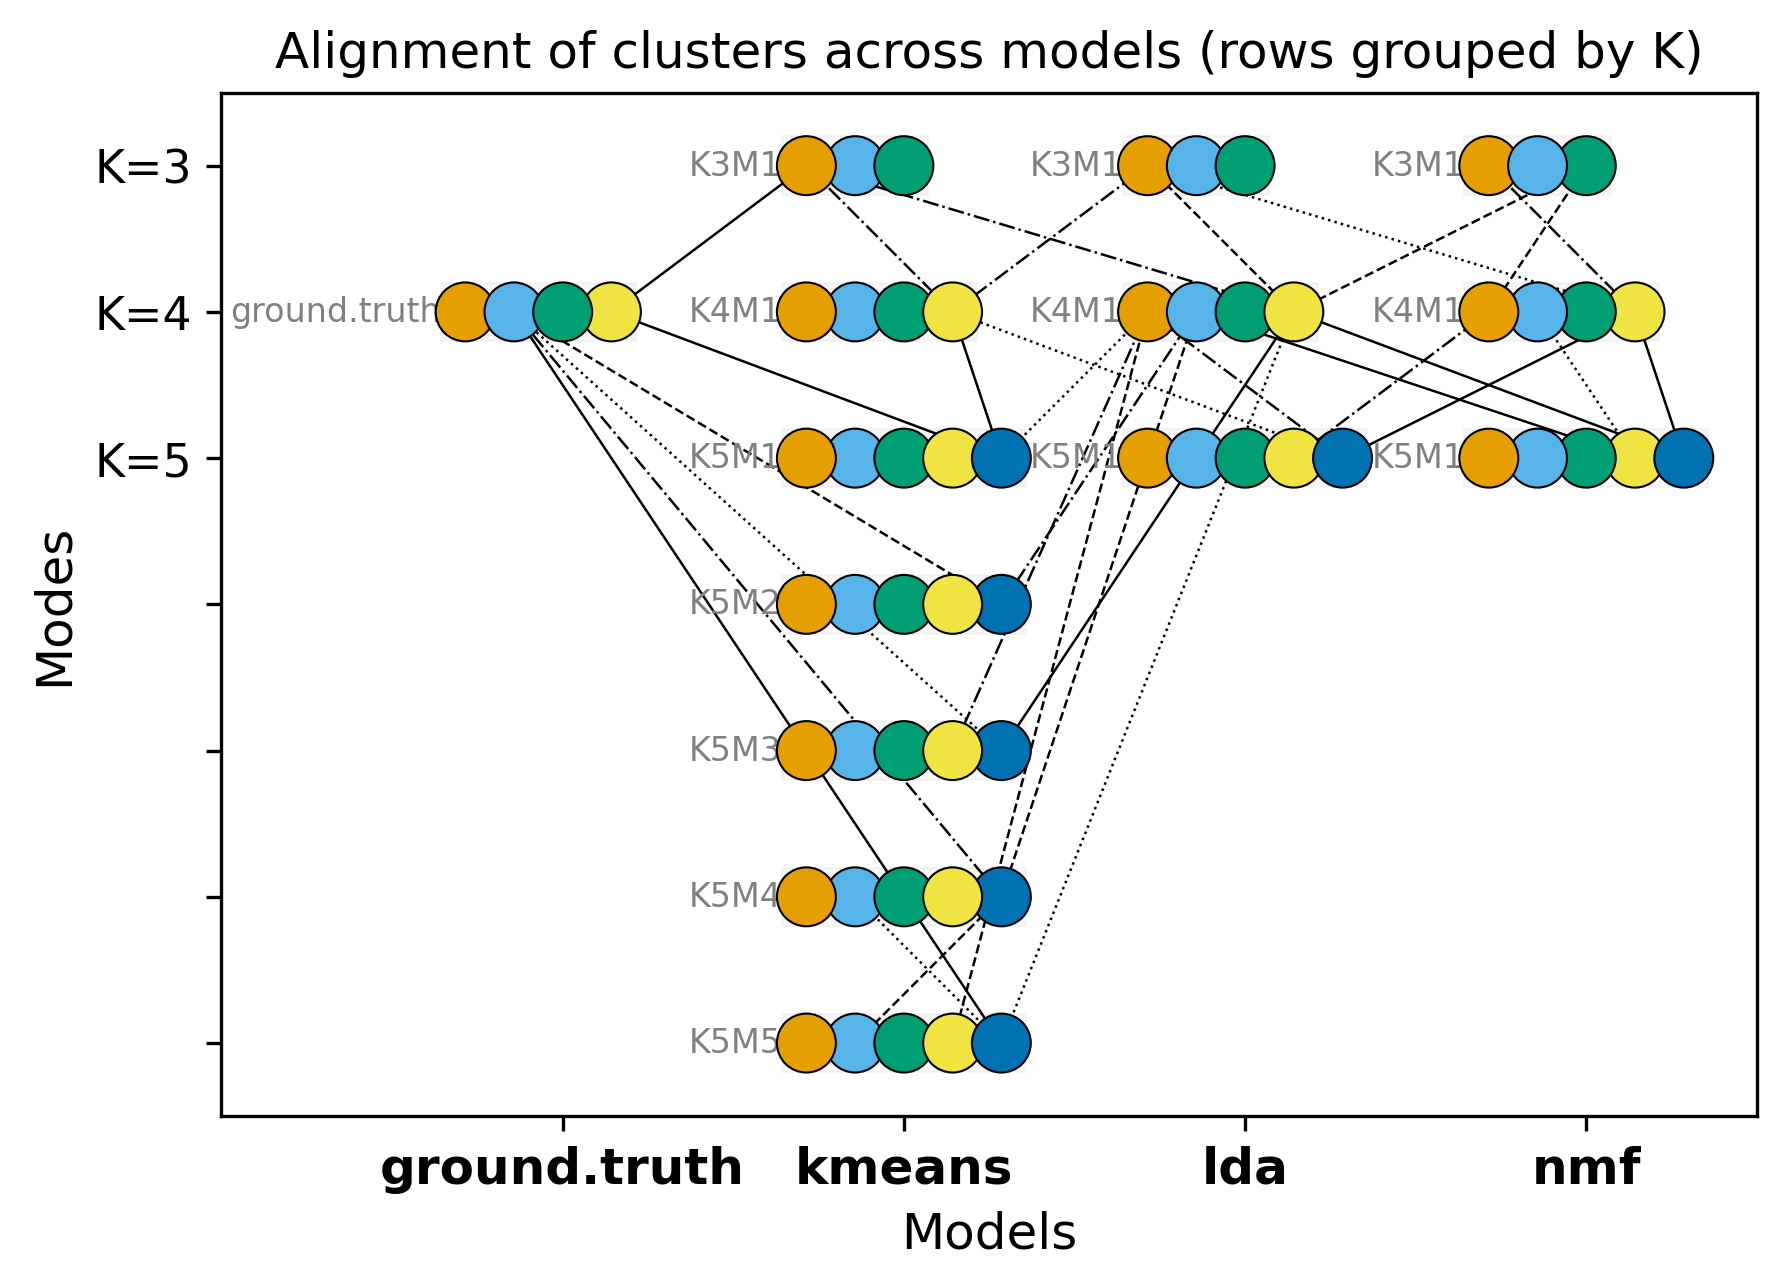

In [48]:
fig, ax = aoc.plot_compmodels_alignment_by_model(
    comp_res,
    cmap=default_colors[:comp_res.K_max],
    pair_mappings=pair_mappings,
    connect_identity=False,  # only highlight non-1–1 / shifted alignments
    adjacent_only=True,      # only between neighboring model columns
    label_modes=True,   # show mode names on the corner
    alt_ls=True, ls_alt=("-", "--", ":", "-."), lw=0.6, # line styles for different K
    figsize_scale=(0.3, 3),
    wspace_padding=1.5,
    dpi=300,
    row_by_K=True, # put modes with same K in the same row
    models_plot_order=models,
)

# update y labels and titles
ax.set_yticklabels(['K=3', 'K=4', 'K=5', '', '', '', ''], fontsize=11)
ax.set_ylabel("Modes", fontsize=12)
ax.set_xlim([-5, None])


### Structure Plots

An alternative when coordinates are not available. Can be slow for large data.

In [49]:
from clumppling.plot import plot_membership

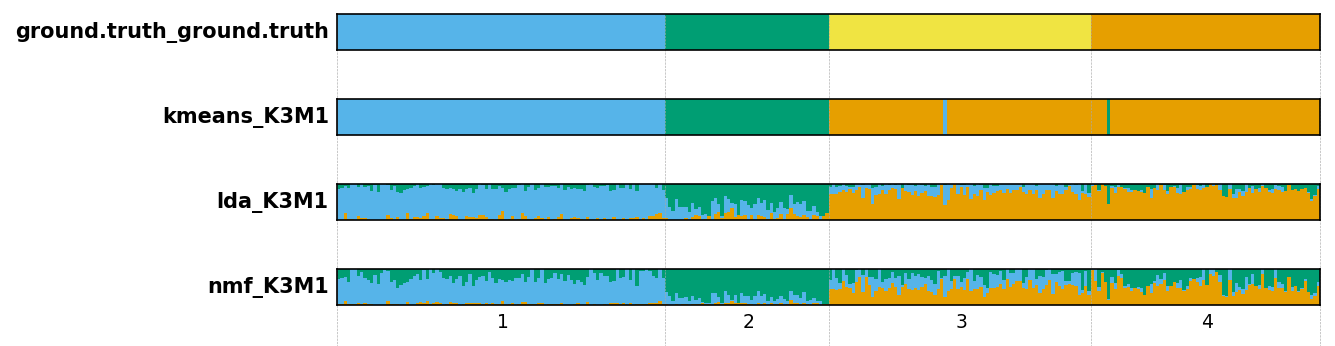

In [50]:
# add ground truth to the modes to plot
modes_to_plot.insert(0, ('ground.truth', 'ground.truth'))

fig = plt.figure(figsize=(9,len(modes_to_plot)*0.7), dpi=150)
gs = fig.add_gridspec(len(modes_to_plot)+1, 1, width_ratios=[1])

for i, mode in enumerate(modes_to_plot):
    mode_full_name = f"{mode[0]}_{mode[1]}"
    ax_membership = fig.add_subplot(gs[i])
    alignedQ = comp_res.Q_by_mode[mode_full_name]
    
    # plot membership as stacked barplot (structure plot)
    plot_membership(alignedQ, default_colors, ax=ax_membership, ylab="", title="", fontsize=14)
    # use the mode full name as y label
    ax_membership.set_ylabel(mode_full_name, fontsize=10, weight='bold', rotation=0, ha='right', va='center')

    # add vertical lines to separate groups based on the cell-reorder reference  mode
    for v in grp_seps:
        ax_membership.axvline(v, ymin=-1.5, ymax=1, color='darkgray', ls='--', lw=0.3, clip_on=False)
    if i==len(modes_to_plot)-1:
        for v in grp_seps:
            ax_membership.set_xticks(grp_indices)
            ax_membership.set_xticklabels(np.arange(len(grp_lbs))+1, fontsize=9, rotation=0)
            ax_membership.tick_params(axis='x', length=0)  
    
fig.tight_layout()


Differences from the reference mode.

In [51]:
mat_diffs = aoc.get_diff_matrices(
    comp_res,
    pair_mappings,
    ref_mode=ref_mode,
    strict_pair_mapping=True,
)

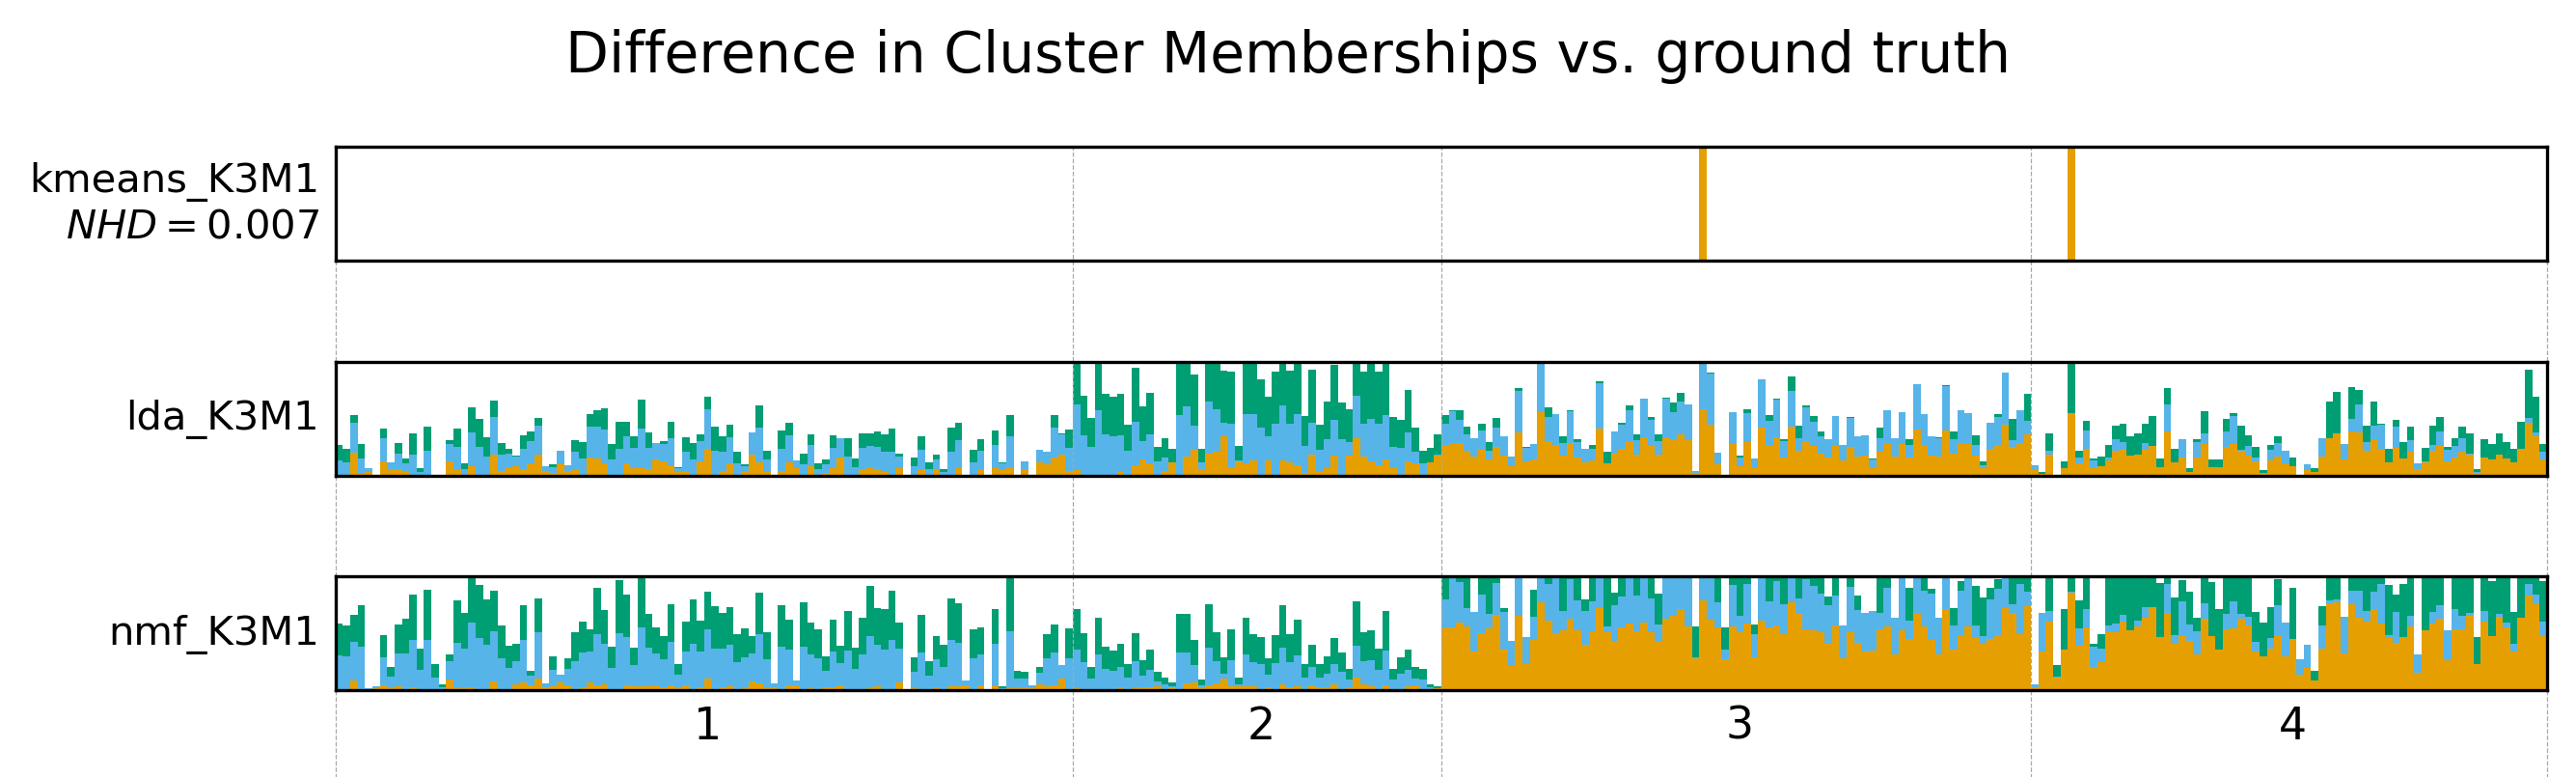

In [52]:
fig = plt.figure(figsize=(9,len(modes_to_plot)), dpi=300)
gs = fig.add_gridspec(len(modes_to_plot)+1, 1, width_ratios=[1])

for i, mode in enumerate(modes_to_plot[1:]):
    mode_full_name = f"{mode[0]}_{mode[1]}"

    ax_diff = fig.add_subplot(gs[i])
    diffQ = mat_diffs[mode[0]][mode[1]]
    # calculate normalized Hamming distance (NHD): for hard-clustering only
    nhd = np.sum(np.sum(diffQ, axis=1)>0.5)/diffQ.shape[0]
    # plot difference membership as stacked barplot (structure plot)
    plot_membership(diffQ, default_colors, ax=ax_diff, ylab="", title="", fontsize=14)
    # use the prepared labels instead
    if mode[0]=="kmeans":
        ax_diff.set_ylabel(mode_full_name+"\n$NHD={:.3f}$".format(nhd), fontsize=10, rotation=0, ha='right', va='center')
    else:
        ax_diff.set_ylabel(mode_full_name, fontsize=10, rotation=0, ha='right', va='center')

    # add vertical lines to separate groups based on cell-reorder reference mode
    for v in grp_seps:
        ax_diff.axvline(v, ymin=-1.5, ymax=1, color='darkgray', ls='--', lw=0.3, clip_on=False)
    if i==len(modes_to_plot[1:])-1:
        for v in grp_seps:
            ax_diff.set_xticks(grp_indices)
            ax_diff.set_xticklabels(np.arange(len(grp_lbs))+1, fontsize=11, rotation=0)
            ax_diff.tick_params(axis='x', length=0)  

fig.suptitle(f"Difference in Cluster Memberships vs. ground truth", fontsize=14)    
fig.tight_layout()

## Comparison with Reference Labels

Differences from the ground truth within each label group.

In [53]:
annotation_group_indices = aoc.get_group_indices(truth_labels)
annotation_group_sizes = aoc.compute_group_sizes(truth_labels)
mode_sizes = aoc.get_mode_sizes(comp_res)

In [54]:
ref_mode = "ground.truth_ground.truth"

modes_total_diff, modes_group_diff = aoc.compute_all_mode_diffs(
    comp_results = comp_res, 
    ref_mode = ref_mode,
    pair_mappings = pair_mappings,
    annotation_labels = truth_labels,
    aggregation = "sum"
)
df_mode_group_diff = aoc.build_diff_df(modes_group_diff)
df_mode_group_diff.head()

,0,1,2,3
ground.truth_ground.truth,0.000000e+00,0.000000e+00,0.0000,0.000000
kmeans_K3M1,2.000000e-09,2.000000e-09,0.0125,0.014286
kmeans_K4M1,3.000000e-09,3.000000e-09,0.3500,0.200000
kmeans_K5M1,4.000000e-09,4.000000e-09,0.3500,0.228571
kmeans_K5M2,3.000000e-09,4.000000e-09,0.4125,0.142857


As a heatmap.

2026-11-05 14:40:44 - INFO     Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-05 14:40:44 - INFO     Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


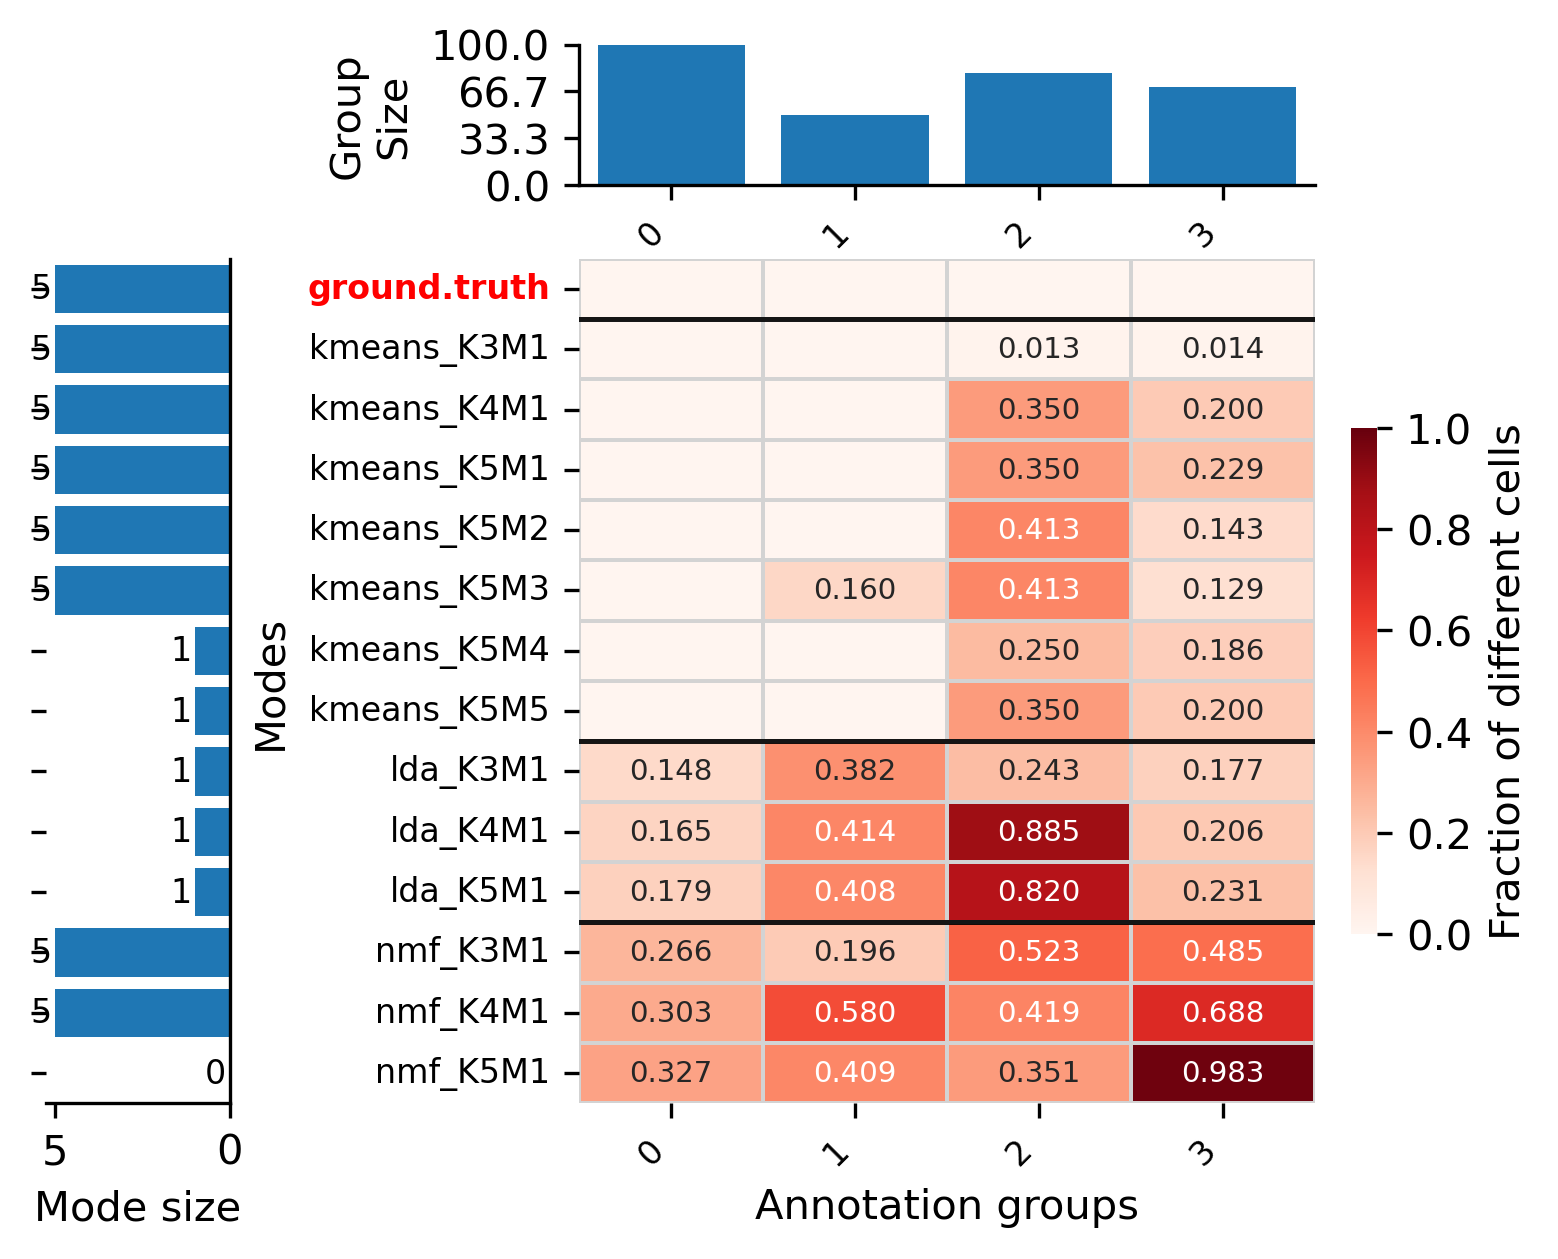

In [55]:
fig, axes = aoc.plot_group_diff(
    df_mode_group_diff,
    mode_sizes=mode_sizes,
    annotation_group_sizes=annotation_group_sizes,
    ref_mode=ref_mode,
    figsize=(5,4),
    top_ylabel="Group\nSize",
    top_round_to=50,
)
# rename mode labels
modes = comp_res.full_mode_names
modes[0] = 'ground.truth'
axes["heatmap"].set_yticklabels(modes, fontsize=8, ha='right')
pass


Selected modes, heatmap only.

Text(0.5, 1.15, 'Difference in Annotation Group \n(Selected Modes)')

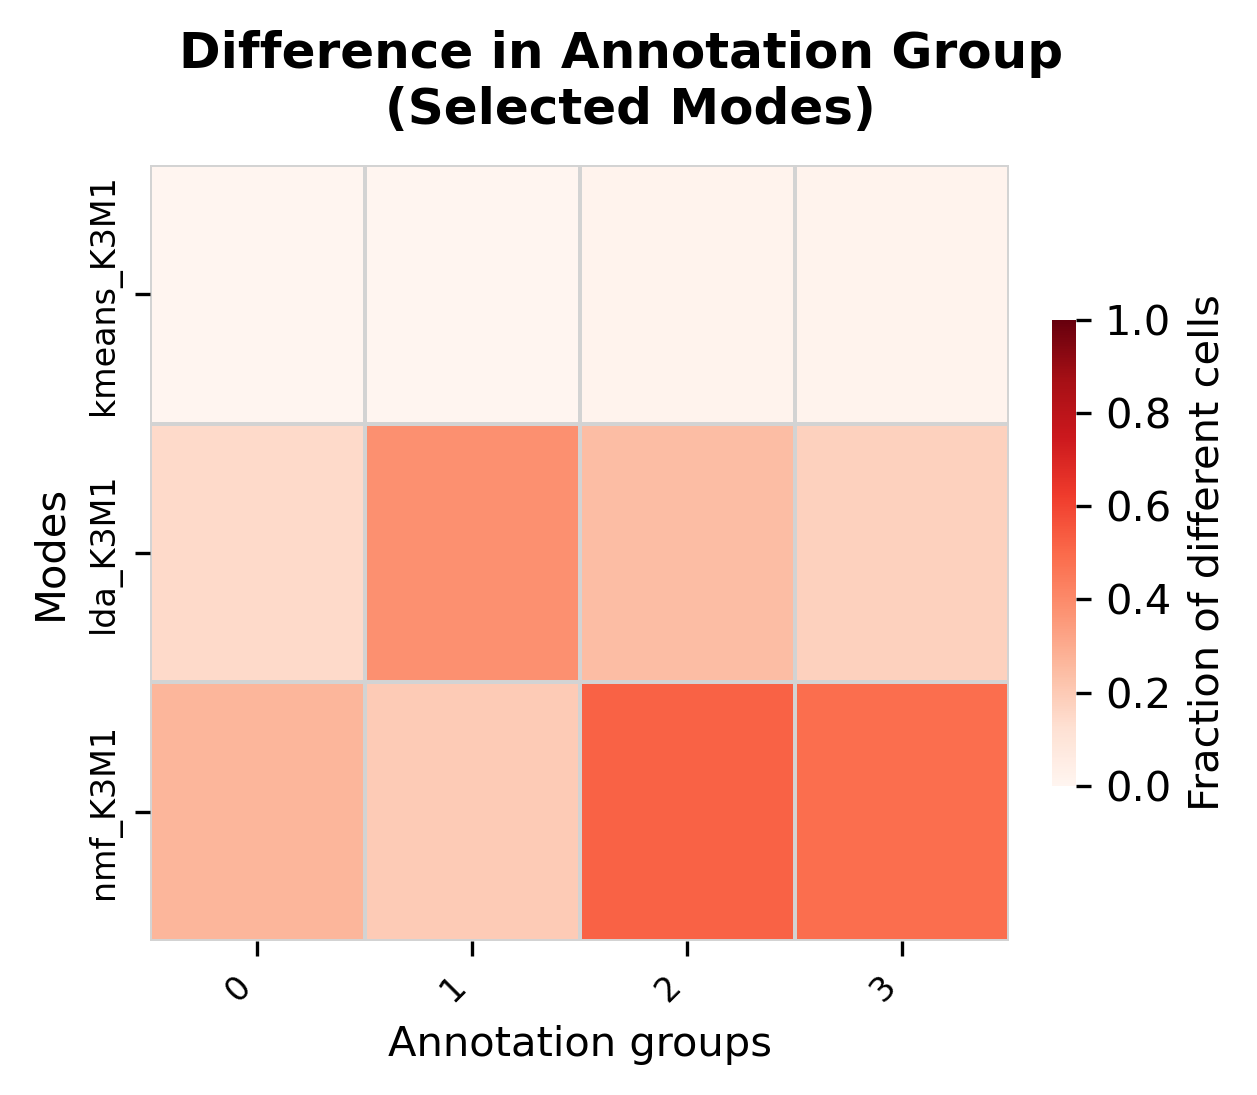

In [56]:
# subset to major modes only
selected_modes = ['kmeans_K3M1', 'lda_K3M1', 'nmf_K3M1']

fig, axes = aoc.plot_group_diff(
    df_mode_group_diff.loc[selected_modes],
    mode_sizes=mode_sizes.loc[selected_modes],
    annotation_group_sizes=annotation_group_sizes,
    ref_mode=ref_mode,
    add_model_separators=False,
    annot=False,
    show_top=False,
    show_left=False,
    figsize=(4,3),
)
fig.suptitle("Difference in Annotation Group \n(Selected Modes)", fontsize=12, weight='bold', y=1.15)
